<a href="https://colab.research.google.com/github/lorenzo-fattori/dtm-dcai/blob/main/slides/lab-06-explainability.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/w4bo/AA2627-unibo-dcai/blob/main/slides/lab-06-explainability.ipynb" target="_parent"><img src="https://github.com/w4bo/AA2627-unibo-dcai/blob/main/slides/img/colab-badge.svg?raw=1" alt="Open In Colab"/></a>


---
title: "Interpretable Machine Learning"
bibliography:
  - refs/refs.bib
---


# Session plan: theory and coding

| Activity |
| --- |
| Theory 1: Logistic contributions, tree rules, and predictive versus structural complexity |
| [Coding 1 (~15 min): Exercises 1 and 2](#coding-exercises-1) |
| Theory 2: Local LIME explanations, Shapley contributions, and TreeSHAP |
| [Coding 2 (~15 min): Exercises 3 and 4](#coding-exercises-2) |
| Theory 3: Global SHAP, explanation limits, reference sensitivity, and neural-network explanations |
| [Coding 3 (~15 min): Exercises 5 and 6](#coding-exercises-3) |

# The interpretability issue

A validation score tells us how often a model predicts well, but leaves its reasoning hidden.

- A predictor can use information recorded after the outcome.
- Different fitted models can reach similar scores using different relationships.
- Understanding depends on the **person and task**, not just the algorithm.

> **Question:** would you deploy a bike-demand model that predicts total rentals?
>
> | Claim | What evidence supports it? |
> | --- | --- |
> | The model predicts well on these later hours | Held-out performance |
> | The model uses temperature in this prediction | A rule, coefficient, or attribution |
> | Raising temperature would increase real demand | A causal study with appropriate assumptions |

# Who needs the explanation?

| Goal | Bike Sharing question | Evidence to seek |
| --- | --- | --- |
| Improve the model | Is there leakage or an encoding bug? | Inputs and rules used |
| Justify model or prediction | Why flag this hour as high demand? | An explanation an operator can inspect |
| Discover insights | Does the model capture commuting patterns? | Patterns across hours and working days |

Choose the **question and audience** before the explanation method.

> A bike operator asks: "Should I prepare for demand during this hour?"
>
> A model developer asks: "Did the model learn a shortcut?"
>
> A researcher asks: "How does the fitted relationship vary by working day?"

# Interpretability Methods

| Approach | Global: model behavior | Local: one prediction |
| --- | --- | --- |
| Interpretable by design | Logistic coefficients; a small tree | Log-odds terms; a tree path |
| Post-hoc, model-agnostic | Permutation importance | LIME; KernelSHAP |
| Post-hoc, model-specific | Aggregate TreeSHAP values | TreeSHAP for a tree or forest |

- **Global:** explain model behavior across many observations, e.g., which features generally drive predicted bike demand.
- **Local:** explain one prediction, e.g., why the model predicts high demand for a particular hour.

In [1]:
#| echo: false
#| output: false

# Run setup before class; installation/download time is outside the coding budget.
import importlib.util
import subprocess
import sys
packages = {"numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib", "sklearn": "scikit-learn>=1.2", "shap": "shap>=0.45", "lime": "lime==0.2.0.1"}
missing = [package for module, package in packages.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
from io import BytesIO
from pathlib import Path
from urllib.request import urlopen
from zipfile import ZipFile
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import balanced_accuracy_score, recall_score
from lime.lime_tabular import LimeTabularExplainer
import shap
RANDOM_STATE = 42
plt.rcParams.update({"figure.dpi": 110, "font.size": 11})


# Working example: [UCI Bike Sharing](https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset) [@fanaeet2013bike]

- `cnt = casual + registered`: exclude all three from predictors.

In [2]:
#| echo: false
archive_path = Path(".cache/datasets/bike-sharing.zip")
archive_path.parent.mkdir(parents=True, exist_ok=True)
if not archive_path.exists():
    url = "https://archive.ics.uci.edu/static/public/275/bike+sharing+dataset.zip"
    with urlopen(url, timeout=60) as response:
        archive_path.write_bytes(response.read())
with ZipFile(BytesIO(archive_path.read_bytes())) as archive:
    member = next(name for name in archive.namelist() if name.endswith("hour.csv"))
    bike = pd.read_csv(archive.open(member), parse_dates=["dteday"])
bike = bike.sort_values(["dteday", "hr"]).reset_index(drop=True)
# Invert the UCI normalization for hour.csv, not day.csv.
X = pd.DataFrame({
    "hour": bike.hr, "workingday": bike.workingday,
    "adverse_weather": (bike.weathersit > 1).astype(int),
    "temperature_C": 47 * bike.temp - 8,
    "humidity_pct": 100 * bike.hum, "windspeed_kmh": 67 * bike.windspeed,
})
y = (bike.cnt >= 200).astype(int).rename("high_demand")
train_mask = bike.dteday < "2012-07-01"
valid_mask = bike.dteday.between("2012-07-01", "2012-09-30")
test_mask = bike.dteday >= "2012-10-01"
X_train, y_train = X.loc[train_mask], y.loc[train_mask]
X_valid, y_valid = X.loc[valid_mask], y.loc[valid_mask]
X_test, y_test = X.loc[test_mask], y.loc[test_mask]
assert len(X_train) + len(X_valid) + len(X_test) == len(bike)
assert not set(X_train.index) & set(X_valid.index)
assert not set(X_valid.index) & set(X_test.index)
display(X_train.head(3).round(1))


,hour,workingday,adverse_weather,temperature_C,humidity_pct,windspeed_kmh
0,0,0,0,3.3,81.0,0.0
1,1,0,0,2.3,80.0,0.0
2,2,0,0,2.3,80.0,0.0


# Does high demand occur at the same hours on working and non-working days?

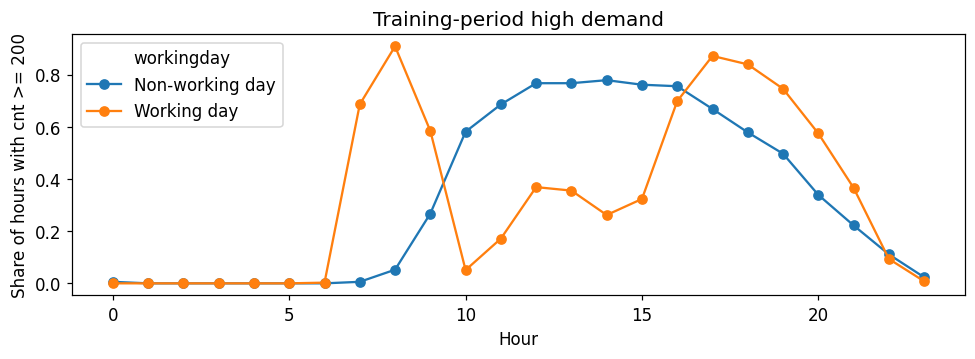

In [3]:
#| echo: false
#| out-height: "350px"
patterns = X_train.assign(high_demand=y_train).groupby(
    ["hour", "workingday"]).high_demand.mean().unstack()
ax = patterns.rename(columns={0: "Non-working day", 1: "Working day"}).plot(
    figsize=(9, 3.4), marker="o")
ax.set(xlabel="Hour", ylabel="Share of hours with cnt >= 200", title="Training-period high demand")
plt.tight_layout()
plt.show()


# Logistic Regression: Add First, Then Convert

For one observation, logistic regression makes a prediction in **two steps**:

1. **Build a score:** multiply each encoded input $z_j(x)$ by its learned coefficient, then add the terms and intercept:

   $$s(x)=\beta_0+\sum_j\beta_j z_j(x).$$

2. **Convert the total score to a probability** using the sigmoid:

   $$p(x)=P(y=1\mid x)=\sigma(s(x))=\frac{1}{1+e^{-s(x)}}.$$

::::{.columns}
:::{.column width="60%"}
The score can be any real number; the probability is between 0 and 1.

- A score of 0 maps to 50%; positive scores map above 50%.
- The score is also called **log-odds**, because $s(x)=\log\!\frac{p(x)}{1-p(x)}$.
:::
:::{.column width="40%"}
![Sigmoid](https://thumb.wikimedia.org/wikipedia/commons/thumb/8/88/Logistic-curve.svg/330px-Logistic-curve.svg.png?utm_source=en.wikipedia.org&utm_campaign=parser&utm_content=thumbnail)
:::
::::

In [4]:
#| echo: false
categorical = ["hour", "workingday", "adverse_weather"]
numeric = ["temperature_C", "humidity_pct", "windspeed_kmh"]
preprocess = ColumnTransformer([
    ("num", StandardScaler(), numeric),
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), categorical),
], verbose_feature_names_out=False)
logistic = Pipeline([("preprocess", preprocess), ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))])
small_tree = DecisionTreeClassifier(max_depth=2, min_samples_leaf=40, random_state=RANDOM_STATE)
forest = RandomForestClassifier(n_estimators=100, max_depth=8, min_samples_leaf=20, random_state=RANDOM_STATE, n_jobs=1)
models = {"Logistic regression": logistic, "Tree depth 2": small_tree, "Forest": forest}
for model in models.values():
    model.fit(X_train, y_train)

def evaluate(model, X_rows, y_rows):
    prediction = model.predict(X_rows)
    return {"balanced_accuracy": balanced_accuracy_score(y_rows, prediction), "high_demand_recall": recall_score(y_rows, prediction)}

comparison = pd.DataFrame({name: evaluate(model, X_valid, y_valid) for name, model in models.items()}).T


# Discussion: Why One-Hot Encode Hour?

Hour is numeric, but demand can have **separate morning and evening peaks**.

- **Raw hour in logistic regression:** a term $\beta_h h$ assumes the same change in log-odds for every one-hour increase, holding other inputs fixed.
- **One-hot encoding (OHE):** each hour gets its own effect relative to hour 0, allowing a flexible hourly pattern.
- **Trade-off:** OHE uses more coefficients and ignores cyclic proximity: 23:00 and 00:00 are adjacent in time but separate categories.
- **Alternatives:** sine/cosine features preserve the daily cycle.


# Read the Fitted Logistic Coefficients

The plot shows the eight largest absolute coefficients, plus `temperature_C`.

- `hour_17` is the score difference between hour 17 and hour 0, holding other inputs fixed.
- `temperature_C` is the score change for one training standard deviation of temperature, holding other inputs fixed.
- A positive coefficient increases the score and hence the predicted probability.
    - Magnitudes depend on encoding and scaling; they are not universal importance scores.


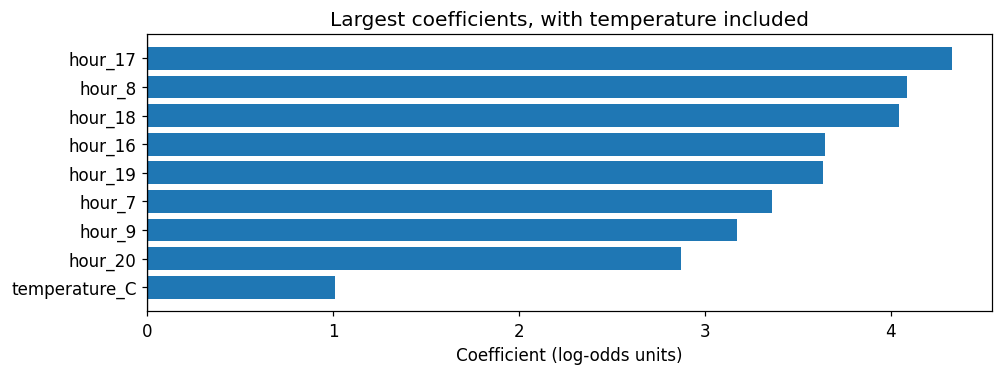

In [5]:
#| echo: false
#| out-height: "350px"
coefs = pd.Series(logistic.named_steps["model"].coef_[0], index=logistic.named_steps["preprocess"].get_feature_names_out())
selected = coefs.abs().nlargest(8).index.tolist()
if "temperature_C" not in selected:
    selected.append("temperature_C")
shown = coefs.loc[selected].sort_values()
fig, ax = plt.subplots(figsize=(9, 3.3), layout="constrained")
ax.barh(shown.index, shown, color=["tab:blue" if v >= 0 else "tab:orange" for v in shown])
ax.axvline(0, color="black", linewidth=.8)
ax.set(xlabel="Coefficient (log-odds units)", title="Largest coefficients, with temperature included")
plt.show()


# Worked Example: Use the Fitted Coefficients

Take the actual validation observation at **17:00 on 2012-07-01**, with temperature **35.24°C**.

| Encoded term | Value $z_j$ | Fitted coefficient | Score contribution |
| --- | ---: | ---: | ---: |
| Intercept | — | $-2.887$ | $-2.887$ |
| `temperature_C` | $2.293$ | $1.011$ | $2.318$ |
| `humidity_pct` | $-1.820$ | $-0.340$ | $0.618$ |
| `windspeed_kmh` | $0.825$ | $-0.159$ | $-0.131$ |
| `hour_17` | $1.000$ | $4.327$ | $4.327$ |
| `workingday_1` | $0.000$ | $-0.059$ | $-0.000$ |
| `adverse_weather_1` | $0.000$ | $-0.332$ | $-0.000$ |

Numeric values are standardized using training statistics; OHE values are 0 or 1. The other hour indicators are all 0.

$$s=\beta_0+\sum_j\beta_j z_j=4.245,\qquad p=\frac{1}{1+e^{-s}}=98.6\%.$$


# The Same Fitted Coefficient, Different Probability Changes

The fitted temperature coefficient is $\beta_T=1.011$. One training standard deviation is **8.99°C**; the training mean is **14.64°C**.

Since $z_T=\frac{T-14.64}{8.99}$, raising temperature by 8.99°C raises $z_T$ by 1 and adds **1.011** to the score.

Start from the actual 00:00 and 17:00 validation observations on 2012-07-01, raise temperature by one training standard deviation:

| Observation | Score change | Probability change | Percentage-point change |
| --- | --- | --- | ---: |
| 00:00 | $-1.227\to-0.215$ | $22.7\%\to44.6\%$ | $+22.0$ |
| 17:00 | $4.245\to5.256$ | $98.6\%\to99.5\%$ | $+0.9$ |

The score increment is the same.

- The probability increment differs because sigmoid depends on the starting score.
- These are controlled model predictions, not causal temperature effects.


# One Prediction, Two Scales: Score and Probability {visibility="hidden"}

These panels show the **same fitted model** while temperature varies and other conditions stay fixed.

- **Left: add contributions.** The temperature term is $\beta_T z_T$. A fixed temperature increase adds a fixed amount to the score: each hour's line is straight.
- **Right: apply sigmoid.** Each left-hand score becomes $p=\frac{1}{1+e^{-s}}$. This bends the response and keeps it between 0 and 1.
- Hour 17 and hour 0 have different score offsets but the same temperature slope: this model has no hour-by-temperature interaction.

The dotted score line $s=0$ corresponds to the dotted probability line $p=0.5$.

- Near probability 0 or 1, the same score change has a smaller probability effect.


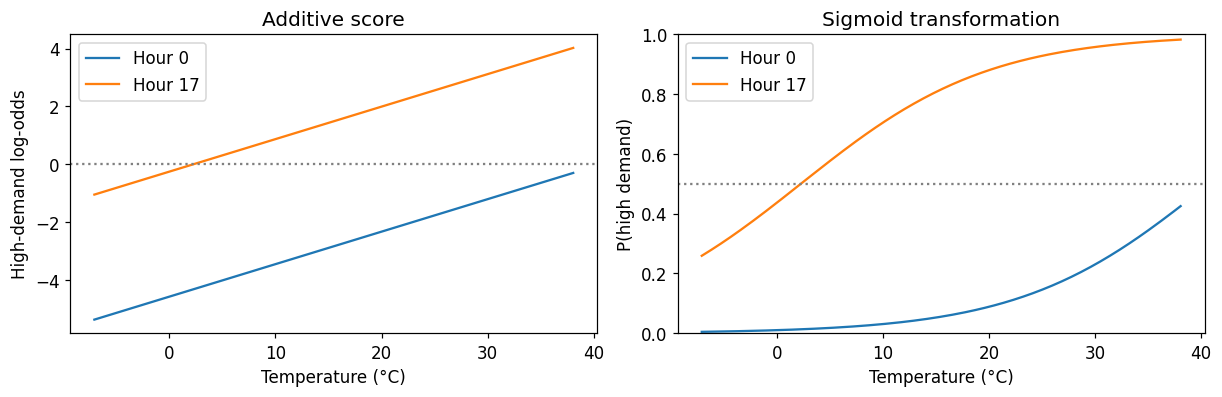

In [6]:
#| echo: false
#| out-height: "360px"
temperature_grid = np.linspace(X_train.temperature_C.min(), X_train.temperature_C.max(), 150)
logistic_slices = {}
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), layout="constrained")
for hour, color in [(0, "tab:blue"), (17, "tab:orange")]:
    probe = pd.DataFrame([X_train.median()] * len(temperature_grid), columns=X.columns)
    probe["hour"], probe["workingday"], probe["adverse_weather"] = hour, 1, 0
    probe["temperature_C"] = temperature_grid
    logits = logistic.decision_function(probe)
    probabilities = logistic.predict_proba(probe)[:, 1]
    logistic_slices[hour] = (logits, probabilities)
    axes[0].plot(temperature_grid, logits, color=color, label=f"Hour {hour}")
    axes[1].plot(temperature_grid, probabilities, color=color, label=f"Hour {hour}")
axes[0].axhline(0, color="gray", linestyle=":")
axes[1].axhline(.5, color="gray", linestyle=":")
axes[0].set(ylabel="High-demand log-odds", title="Additive score")
axes[1].set(ylabel="P(high demand)", ylim=(0, 1), title="Sigmoid transformation")
for ax in axes:
    ax.set_xlabel("Temperature (°C)")
    ax.legend()
plt.show()


# Coefficients Become Contributions When Inputs Are Known {visibility="hidden"}

A **coefficient** $\beta_j$ is a learned multiplier. Its **contribution** also depends on the encoded value for the observation being explained.

To compare one hour with the training population, let $\mu_j$ be the training mean of encoded input $j$:

$$c_j(x)=\beta_j\bigl(z_j(x)-\mu_j\bigr),\qquad s_{\mathrm{ref}}=\beta_0+\sum_j\beta_j\mu_j.$$

- $c_j(x)$ measures how far this input moves the score from that reference.
- Add the reference score and all contributions to reconstruct the score, then apply sigmoid **once**:

  $$s(x)=s_{\mathrm{ref}}+\sum_j c_j(x),\qquad p(x)=\sigma\!\left(s_{\mathrm{ref}}+\sum_j c_j(x)\right).$$

# Logistic Regression: Local Terms and a Global Summary {visibility="hidden"}

- **Left:** signed contributions for one validation observation, relative to the training mean. Positive bars raise its score; negative bars lower it.
- **Right:** average absolute contribution over validation observations.
    - For **hour**, sum its OHE contributions before taking the absolute value.

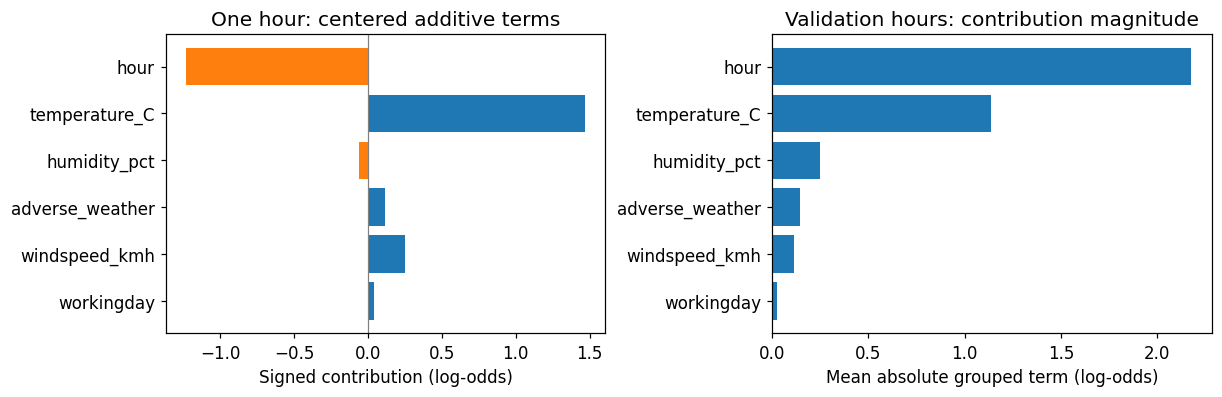

In [7]:
#| echo: false
#| out-height: "360px"
linear_training_design = logistic.named_steps["preprocess"].transform(X_train)
linear_valid_design = logistic.named_steps["preprocess"].transform(X_valid)
linear_reference = linear_training_design.mean(axis=0)
linear_beta = logistic.named_steps["model"].coef_[0]
linear_base_logit = float(logistic.named_steps["model"].intercept_[0] + linear_reference @ linear_beta)
linear_terms = (linear_valid_design - linear_reference) * linear_beta
# The preprocessing emits numeric columns first, followed by each dummy block.
encoder = logistic.named_steps["preprocess"].named_transformers_["cat"]
linear_groups = list(numeric)
for name, levels, dropped in zip(categorical, encoder.categories_, encoder.drop_idx_):
    linear_groups.extend([name] * (len(levels) - int(dropped is not None)))
assert len(linear_groups) == linear_terms.shape[1]
linear_grouped_terms = pd.DataFrame(linear_terms, index=X_valid.index, columns=linear_groups).T.groupby(
    level=0, sort=False).sum().T
linear_global_importance = linear_grouped_terms.abs().mean().sort_values()
local_terms = linear_grouped_terms.iloc[0].reindex(linear_global_importance.index)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), layout="constrained")
axes[0].barh(local_terms.index, local_terms,
    color=["tab:blue" if value >= 0 else "tab:orange" for value in local_terms])
axes[0].axvline(0, color="gray", linewidth=.8)
axes[0].set(xlabel="Signed contribution (log-odds)", title="One hour: centered additive terms")
axes[1].barh(linear_global_importance.index, linear_global_importance, color="tab:blue")
axes[1].set(xlabel="Mean absolute grouped term (log-odds)", title="Validation hours: contribution magnitude")
plt.show()


# Decision tree

![Decision tree](https://github.com/w4bo/AA2627-unibo-dcai/blob/main/slides/img/dt.png?raw=1)


# Decision tree: rules and paths

Trace a path from root to leaf. What information does the model ignore on that path?

- Each split asks a threshold question; a path joins conditions with **AND**.
- A leaf's class fraction estimates high-demand probability here; it is not automatically calibrated.
- Trees can learn interactions without explicitly creating interaction features.
- A small tree is inspectable; many leaves make the full model difficult to read.


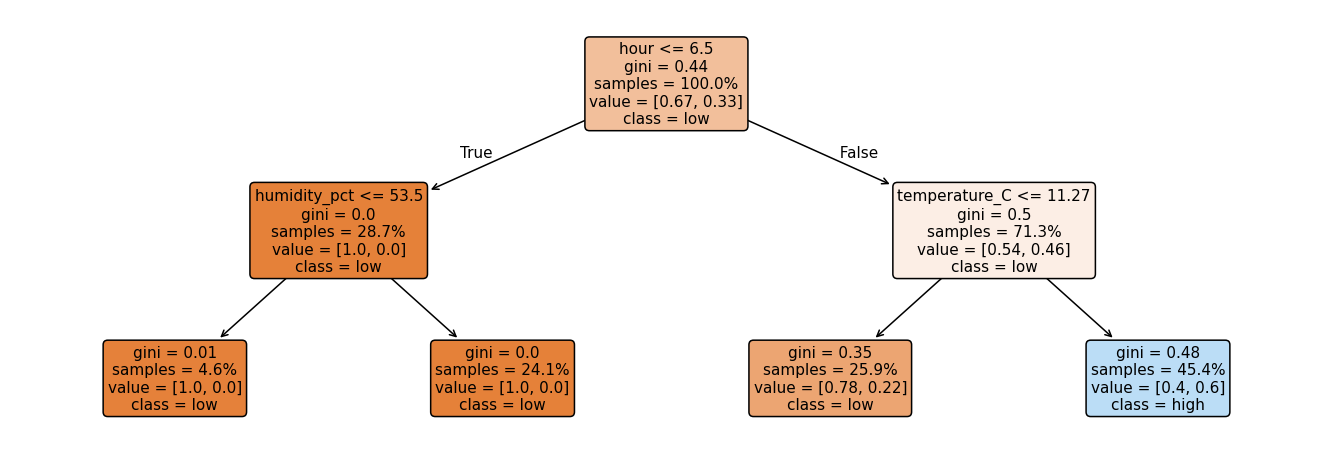

In [8]:
#| echo: false
#| out-height: "390px"
fig, ax = plt.subplots(figsize=(12, 4.1), layout="constrained")
plot_tree(small_tree, feature_names=X.columns.tolist(), class_names=["low", "high"],
          filled=True, rounded=True, proportion=True, precision=2, fontsize=10, ax=ax)
plt.show()


# How the tree chooses a split

For the root's selected feature, compare candidate thresholds using weighted child **Gini impurity**.

- The learner favors purer child groups, subject to constraints such as minimum leaf size.

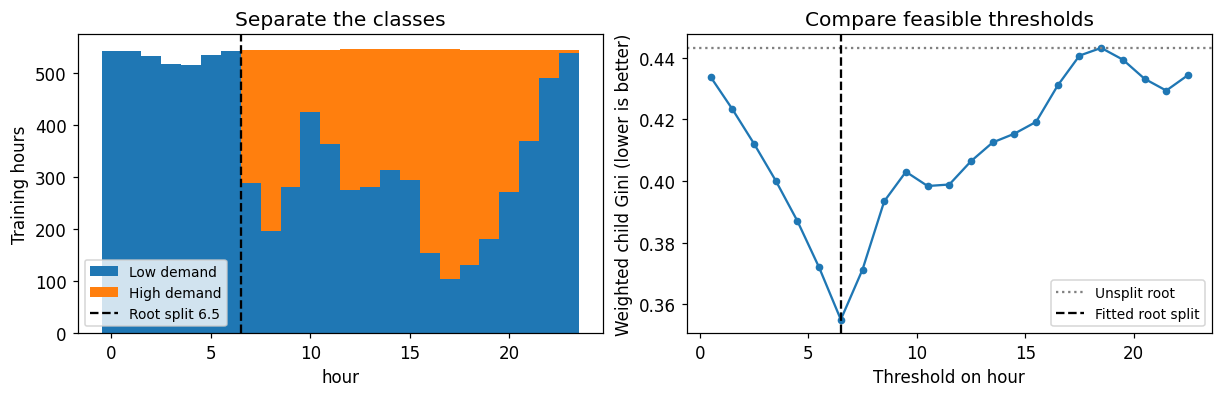

In [9]:
#| echo: false
#| out-height: "360px"
root_feature = X.columns[small_tree.tree_.feature[0]]
root_threshold = float(small_tree.tree_.threshold[0])
values = X_train[root_feature].to_numpy()
levels = np.unique(values)
thresholds = (levels[:-1] + levels[1:]) / 2

def gini(labels):
    positive_share = np.mean(labels)
    return 2 * positive_share * (1 - positive_share)

split_rows = []
for threshold in thresholds:
    left = values <= threshold
    if min(left.sum(), (~left).sum()) < small_tree.min_samples_leaf:
        continue
    cost = (left.mean() * gini(y_train.to_numpy()[left])
            + (~left).mean() * gini(y_train.to_numpy()[~left]))
    split_rows.append((threshold, cost))
split_curve = pd.DataFrame(split_rows, columns=["threshold", "weighted_gini"])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), layout="constrained")
axes[0].hist([values[y_train.to_numpy() == 0], values[y_train.to_numpy() == 1]],
    bins=np.r_[levels[0] - .5, thresholds, levels[-1] + .5],
    stacked=True, label=["Low demand", "High demand"], color=["tab:blue", "tab:orange"])
axes[0].axvline(root_threshold, color="black", linestyle="--", label=f"Root split {root_threshold:g}")
axes[0].set(xlabel=root_feature, ylabel="Training hours", title="Separate the classes")
axes[0].legend(fontsize=9)
axes[1].plot(split_curve.threshold, split_curve.weighted_gini, marker="o", markersize=4)
axes[1].axhline(gini(y_train), color="gray", linestyle=":", label="Unsplit root")
axes[1].axvline(root_threshold, color="black", linestyle="--", label="Fitted root split")
axes[1].set(xlabel=f"Threshold on {root_feature}", ylabel="Weighted child Gini (lower is better)",
            title="Compare feasible thresholds")
axes[1].legend(fontsize=9)
plt.show()


# Decision tree: importance from impurity reduction

For split node $t$, let $N_t$ be the **number of training records reaching that node** and $G(t)$ its Gini impurity.

- Assume all records have equal weight.

$N$ is the total number of training records; $N_L$ and $N_R$ count those reaching the left and right children. The split's credit $\Delta_t$ is

$$\Delta_t=\frac{N_t}{N}\left[G(t)-\frac{N_L}{N_t}G(L)-\frac{N_R}{N_t}G(R)\right].$$

1. Credit the feature used at that node with $\Delta_t$.
2. Sum its credits over **all split nodes** in the fitted tree.
3. Normalize feature totals to sum to one when total reduction is positive.

This is `feature_importances_`: a **global training statistic**

- It has no direction and does not explain one prediction's probability.


# Tree importance: training credit versus validation reliance

**Why temperature has zero permutation importance here?**

:::{.fragment}
The split threshold is 11.27°C, but all validation temperatures are at least 11.74°C.

- Shuffling them never changes the branch taken.
- Its training impurity importance can still be high. *Why*?
:::

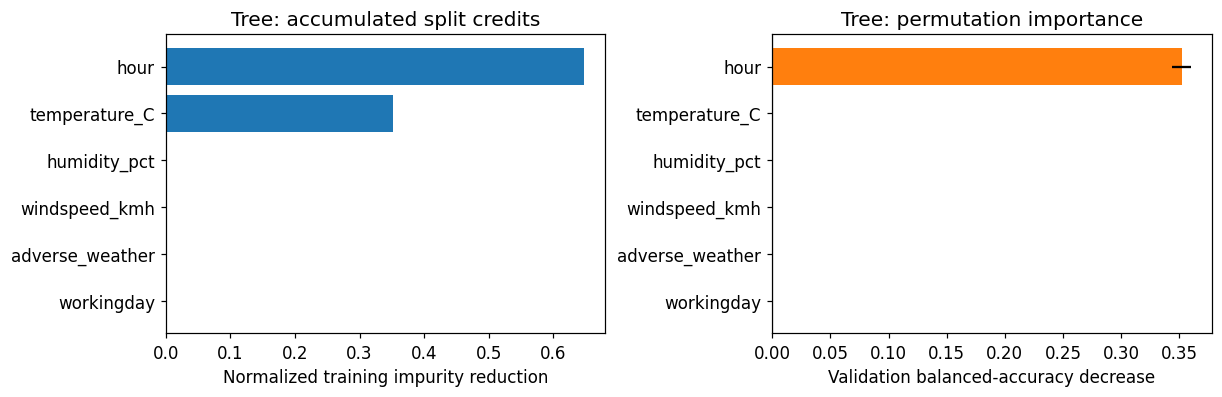

In [10]:
#| echo: false
#| out-height: "360px"
from sklearn.inspection import permutation_importance
tree_structure = small_tree.tree_
node_credits = []
for node, feature_index in enumerate(tree_structure.feature):
    if feature_index < 0:
        continue
    left, right = tree_structure.children_left[node], tree_structure.children_right[node]
    mass = tree_structure.weighted_n_node_samples
    reduction = (mass[node] * tree_structure.impurity[node]
        - mass[left] * tree_structure.impurity[left]
        - mass[right] * tree_structure.impurity[right]) / mass[0]
    node_credits.append({"node": node, "feature": X.columns[feature_index], "credit": reduction})
node_credits = pd.DataFrame(node_credits)
mdi = node_credits.groupby("feature").credit.sum().reindex(X.columns, fill_value=0)
mdi = mdi / mdi.sum()
tree_permutation = permutation_importance(small_tree, X_valid, y_valid,
    scoring="balanced_accuracy", n_repeats=5, random_state=RANDOM_STATE)
importance_order = mdi.sort_values().index
permutation_mean = pd.Series(tree_permutation.importances_mean, index=X.columns).reindex(importance_order)
permutation_std = pd.Series(tree_permutation.importances_std, index=X.columns).reindex(importance_order)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), layout="constrained")
axes[0].barh(importance_order, mdi.reindex(importance_order), color="tab:blue")
axes[0].set(xlabel="Normalized training impurity reduction", title="Tree: accumulated split credits")
axes[1].barh(importance_order, permutation_mean, xerr=permutation_std, color="tab:orange")
axes[1].axvline(0, color="gray", linewidth=.8)
axes[1].set(xlabel="Validation balanced-accuracy decrease", title="Tree: permutation importance")
plt.show()


# Logistic regression versus a small tree

| | Logistic regression | Small decision tree |
| --- | --- | --- |
| Representation | Additive log-odds | Threshold rules |
| Nonlinear relationships | Engineer suitable input terms | Learned piecewise |
| Interactions | Add interaction terms | Learned along paths |
| Local reading | Sum transformed feature terms | Follow one path |
| Main readability limit | Too many coefficients | Too many rules |


# Which procedure could you reproduce by hand?

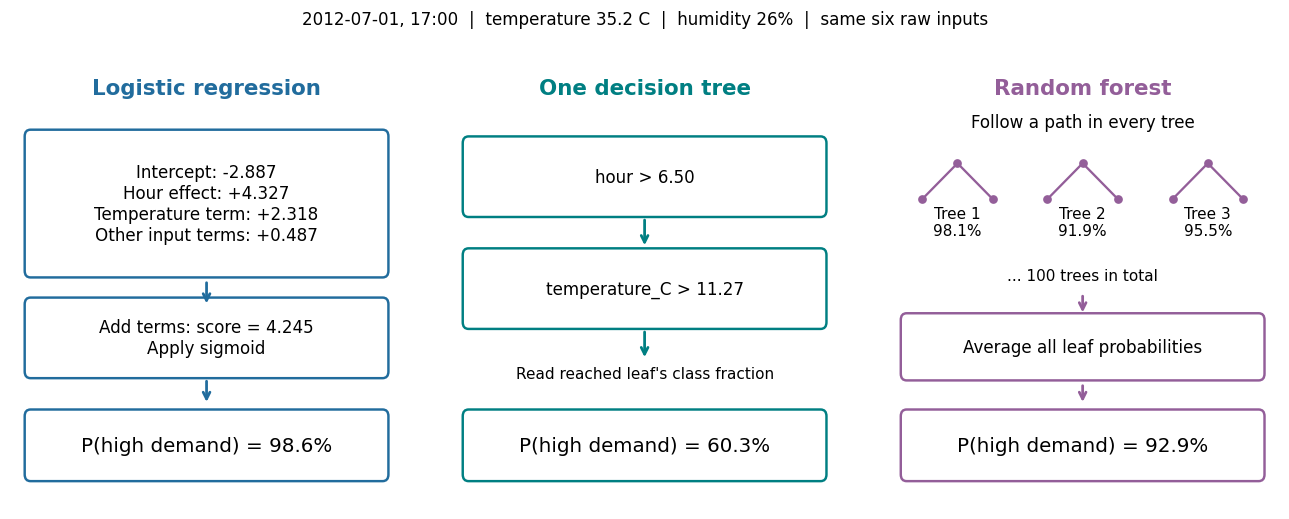

In [11]:
#| echo: false
#| out-height: "430px"
from matplotlib.patches import FancyBboxPatch

# Follow the same actual validation observation through all three fitted models.
process_x = X_valid.loc[X_valid.hour.eq(17)].iloc[[0]]
process_design = logistic["preprocess"].transform(process_x)[0]
process_names = logistic["preprocess"].get_feature_names_out()
process_terms = pd.Series(process_design * logistic["model"].coef_[0], index=process_names)
process_intercept = float(logistic["model"].intercept_[0])
process_score = float(logistic.decision_function(process_x)[0])
process_hour = float(process_terms.filter(like="hour_").sum())
process_temp = float(process_terms["temperature_C"])
process_rest = float(process_terms.sum() - process_hour - process_temp)
process_probabilities = [float(model.predict_proba(process_x)[0, 1])
                         for model in [logistic, small_tree, forest]]
process_rules = []
for node in small_tree.decision_path(process_x).indices:
    feature = small_tree.tree_.feature[node]
    if feature >= 0:
        name = X.columns[feature]
        threshold = small_tree.tree_.threshold[node]
        direction = "<=" if process_x.iloc[0, feature] <= threshold else ">"
        process_rules.append(f"{name} {direction} {threshold:.2f}")
process_forest_probs = np.array([tree.predict_proba(process_x.to_numpy())[0, 1]
                                 for tree in forest.estimators_])

process_fig, process_axes = plt.subplots(1, 3, figsize=(12, 5.5))
process_colors = ["#216C9D", "#007F82", "#935E99"]
def process_box(ax, y, text, color, height=0.15, fontsize=11):
    ax.add_patch(FancyBboxPatch((0.05, y-height/2), 0.90, height,
        boxstyle="round,pad=0.015", facecolor="white", edgecolor=color, linewidth=1.6))
    ax.text(0.5, y, text, ha="center", va="center", fontsize=fontsize)
def process_arrow(ax, start, end, color):
    ax.annotate("", xy=(0.5, end), xytext=(0.5, start),
                arrowprops=dict(arrowstyle="->", color=color, lw=1.8))
for ax, title, color in zip(process_axes,
        ["Logistic regression", "One decision tree", "Random forest"], process_colors):
    ax.set(xlim=(0, 1), ylim=(0, 1)); ax.axis("off")
    ax.text(0.5, 0.96, title, ha="center", va="top", weight="bold", fontsize=14, color=color)

ax=process_axes[0]; color=process_colors[0]
process_box(ax, 0.68,
    f"Intercept: {process_intercept:+.3f}\nHour effect: {process_hour:+.3f}\n"
    f"Temperature term: {process_temp:+.3f}\nOther input terms: {process_rest:+.3f}",
    color, height=0.30)
process_arrow(ax, 0.51, 0.45, color)
process_box(ax, 0.38, f"Add terms: score = {process_score:.3f}\nApply sigmoid", color)
process_arrow(ax, 0.29, 0.23, color)

ax=process_axes[1]; color=process_colors[1]
assert len(process_rules)==2
process_box(ax, 0.74, process_rules[0], color)
process_arrow(ax, 0.65, 0.58, color)
process_box(ax, 0.49, process_rules[1], color)
process_arrow(ax, 0.40, 0.33, color)
ax.text(0.5, 0.29, "Read reached leaf's class fraction", ha="center", fontsize=10)

ax=process_axes[2]; color=process_colors[2]
for k, cx in enumerate([0.18, 0.50, 0.82]):
    for dx in [-0.09, 0.09]:
        ax.plot([cx, cx+dx], [0.77, 0.69], color=color, lw=1.5)
    ax.scatter([cx, cx-0.09, cx+0.09], [0.77, 0.69, 0.69], color=color, s=22)
    ax.text(cx, 0.61, f"Tree {k+1}\n{process_forest_probs[k]:.1%}", ha="center", fontsize=10)
ax.text(0.5, 0.85, "Follow a path in every tree", ha="center", fontsize=11)
ax.text(0.5, 0.51, f"... {len(forest.estimators_)} trees in total", ha="center", fontsize=10)
process_arrow(ax, 0.48, 0.43, color)
process_box(ax, 0.36, "Average all leaf probabilities", color, height=0.12)
process_arrow(ax, 0.28, 0.23, color)

for ax, color, probability in zip(process_axes, process_colors, process_probabilities):
    process_box(ax, 0.14, f"P(high demand) = {probability:.1%}", color, height=0.13, fontsize=13)
process_date = bike.loc[process_x.index[0], "dteday"].strftime("%Y-%m-%d")
process_fig.text(0.5, 0.90,
    f"{process_date}, 17:00  |  temperature {process_x.temperature_C.iloc[0]:.1f} C  |  "
    f"humidity {process_x.humidity_pct.iloc[0]:.0f}%  |  same six raw inputs",
    ha="center", fontsize=11)
process_fig.subplots_adjust(top=0.84, bottom=0.10, left=0.02, right=0.98, wspace=0.12)
plt.show()


# Does improved prediction quality justify a model harder to simulate?

- **Prediction quality:** balanced accuracy and high-demand recall compare predictions with observed labels.
- **Structural complexity:** global coefficients, rules and leaves; local terms or split checks needed for one prediction [@lipton2018mythos].
- **Human simulatability:** measure how accurately and quickly people reproduce model predictions. The counts below are proxies, not a human evaluation [@doshivelez2017towards; @poursabzi2021manipulating].


In [12]:
#| echo: false
# A single table combines predictive quality with global/local complexity proxies.
beta = logistic["model"].coef_[0]
encoded_names = logistic["preprocess"].get_feature_names_out()
nonzero = np.abs(beta) > 1e-12
logistic_used_inputs = sum(any(nonzero & ((encoded_names == name) |
    np.array([encoded.startswith(name + "_") for encoded in encoded_names])))
    for name in X_train.columns)
encoded_valid = logistic["preprocess"].transform(X_valid)
active_logistic_terms = (np.abs(encoded_valid * beta) > 1e-12).sum(axis=1)
tree_checks = np.asarray(small_tree.decision_path(X_valid).sum(axis=1)).ravel() - 1
forest_checks = np.zeros(len(X_valid))
forest_used_features = set()
forest_splits = 0
forest_leaves = 0
for estimator in forest.estimators_:
    split_features = estimator.tree_.feature[estimator.tree_.feature >= 0]
    forest_used_features.update(split_features.tolist())
    forest_splits += len(split_features)
    forest_leaves += estimator.get_n_leaves()
    forest_checks += np.asarray(
        estimator.decision_path(X_valid.to_numpy()).sum(axis=1)).ravel() - 1
small_tree_features = small_tree.tree_.feature[small_tree.tree_.feature >= 0]
metric_labels = ["Balanced accuracy", "High-demand recall", "Original inputs used",
                 "Global learned structure", "Leaves (sum across trees)",
                 "Mean local work (validation)", "Max local work (validation)"]
performance_vs_simulatability = pd.DataFrame({
    "Logistic regression": [
        f'{comparison.loc["Logistic regression", "balanced_accuracy"]:.3f}',
        f'{comparison.loc["Logistic regression", "high_demand_recall"]:.3f}',
        int(logistic_used_inputs), f"{nonzero.sum()} coefficients + intercept", "Not applicable",
        f"{active_logistic_terms.mean():.2f} terms", f"{active_logistic_terms.max()} terms"],
    "Depth-2 tree": [
        f'{comparison.loc["Tree depth 2", "balanced_accuracy"]:.3f}',
        f'{comparison.loc["Tree depth 2", "high_demand_recall"]:.3f}',
        len(set(small_tree_features)), f"{len(small_tree_features)} split rules",
        small_tree.get_n_leaves(), f"{tree_checks.mean():.2f} split checks",
        f"{int(tree_checks.max())} split checks"],
    "Random forest": [
        f'{comparison.loc["Forest", "balanced_accuracy"]:.3f}',
        f'{comparison.loc["Forest", "high_demand_recall"]:.3f}',
        len(forest_used_features), f"{len(forest.estimators_)} trees; {forest_splits:,} splits",
        f"{forest_leaves:,}", f"{forest_checks.mean():.2f} split checks",
        f"{int(forest_checks.max())} split checks"],
}, index=metric_labels)
display(performance_vs_simulatability)


,Logistic regression,Depth-2 tree,Random forest
Balanced accuracy,0.883,0.857,0.906
High-demand recall,0.869,0.995,0.867
Original inputs used,6,3,6
Global learned structure,28 coefficients + intercept,3 split rules,"100 trees; 8,769 splits"
Leaves (sum across trees),Not applicable,4,"8,869"
Mean local work (validation),4.92 terms,2.00 split checks,660.59 split checks
Max local work (validation),6 terms,2 split checks,800 split checks


{{< include _coding_break1.qmd >}}


# Local explanations for a fixed forest

<a id="theory-block-2"></a>

We explain its **high-demand probability** for one fixed validation hour.

- LIME fits a simple surrogate near this observation.
- SHAP allocates the prediction minus a reference output among features.

In [13]:
#| echo: false
row_position = 854
x = X_valid.iloc[[row_position]]
display(x.assign(observed_high=int(y_valid.iloc[row_position]), forest_probability=float(forest.predict_proba(x)[0, 1])).round(3))


,hour,workingday,adverse_weather,temperature_C,humidity_pct,windspeed_kmh,observed_high,forest_probability
13857,14,0,0,34.3,42.0,31.001,1,0.787


# LIME: Local Interpretable Model-agnostic Explanations

# Explain One Forest Prediction

**LIME** learns a small explanatory model for one observation [@ribeiro2016should].

> A forest combines 100 trees.
> For **14:00 on 5 August 2012**, its inputs include hour 14, temperature **34.30°C**, humidity **42%**, and a non-working-day flag.
> Which input conditions help explain the forest's high-demand probability for this observation?

We want a short explanation of this one prediction that an operator can inspect.



# LIME: Explain One Forest Prediction

Imagine asking the forest many questions about alternative input rows:

- What does it predict for another hour of the day?
- What does it predict with a different temperature or working-day flag?

LIME samples many such rows and records the **forest's answers**.

- It then teaches a small linear model to imitate those answers, giving greater weight to rows similar to the observation we are explaining.
- This small model is the **surrogate**: a stand-in for the forest around one observation.
- We read its few coefficients to see which conditions support or oppose a high-demand prediction.

**Local** means that agreement matters most around this observation.

- The same surrogate may work poorly elsewhere.

# LIME: Agreement Plus Simplicity

Choose a simple model that closely imitates the forest around the observation we want to explain [@ribeiro2016should].

$$g_x=\arg\min_{g\in G}\left[L(f,g,\pi_x)+\Omega(g)\right].$$

| Symbol | Meaning |
| --- | --- |
| $x$ | The one observation being explained |
| $f$ | The trained forest's high-demand probability function |
| $g\in G$ | One candidate surrogate from the family $G$ of allowed simple models |
| $\pi_x$ | Weights expressing how similar sampled observations are to $x$ |
| $L(f,g,\pi_x)$ | How much the surrogate disagrees with the forest, emphasizing similar observations |
| $\Omega(g)$ | A penalty or restriction keeping the surrogate small |
| $\arg\min$, $g_x$ | Select the model with the smallest total; call that fitted model $g_x$ |


# LIME: The Formula Used by Tabular Surrogate

$$\min_{b_0,b}\underbrace{\sum_{i=1}^{M}w_i\left[y_i-(b_0+b^\top z_i')\right]^2}_{\text{imitate forest answers nearby}}+\underbrace{\lambda\sum_j b_j^2}_{\text{shrink coefficients}}.$$

| Symbol | Plain meaning |
| --- | --- |
| $M$, $i$ | Number of sampled rows; $i$ identifies one sampled row |
| $z_i$, $y_i=f(z_i)$ | A sampled raw row and the forest's answer for it |
| $z_i'=h_x(z_i)$ | Standardized numeric inputs and yes/no category matches; only selected terms enter the fit |
| $b_0$, $b$, $b^\top z_i'$ | Surrogate intercept, coefficients, and the sum of coefficient × encoded-input terms |
| $w_i=\exp[-\frac{d_i^2}{2\sigma^2}]$ | How strongly row $i$ influences the fit |
| $d_i$ | Distance in standardized inputs and category matches |
| $\lambda$ | Strength of coefficient shrinkage |
| $y_i$ | Forest probabilities |


# LIME: The Approach in Our Bike Example

1. **Choose the observation:** 14:00 on 5 August 2012, 34.30°C, 42% humidity, non-working day.
2. **Sample 5,000 alternative rows** around its numeric inputs. Include the original observation.
3. **Ask the forest for a probability** on every sampled row..
4. **Encode inputs:** standardize numeric fields; encode whether working-day and adverse-weather flags match the observation.
5. **Weight similar rows more strongly** using kernel width 0.5, select four terms, and fit the small linear surrogate.
6. **Read its coefficients and check its fit.** Repeat with another seed to check stability.

`num_features=4` keeps the explanation short. Numeric fields remain continuous here; they are not converted into temperature intervals.


In [14]:
#| echo: false
feature_names = X.columns.tolist()
category_positions = [feature_names.index(name) for name in ["workingday", "adverse_weather"]]

def forest_proba(values):
    rows = pd.DataFrame(values, columns=feature_names)
    rows["hour"] = rows["hour"].round().clip(0, 23)
    return forest.predict_proba(rows)


In [15]:
def make_lime_explainer(seed=42, kernel_width=0.5):
    return LimeTabularExplainer(
        X_train.to_numpy(), feature_names=feature_names,
        class_names=["low demand", "high demand"], categorical_features=category_positions,
        mode="classification", discretize_continuous=False,
        sample_around_instance=True, kernel_width=kernel_width, random_state=seed)

def explain_lime(row, seed=42, num_features=4, num_samples=5000,
                 kernel_width=0.5, model_regressor=None):
    return make_lime_explainer(seed, kernel_width).explain_instance(
        row.iloc[0].to_numpy(), forest_proba, labels=(1,), num_features=num_features,
        num_samples=num_samples, model_regressor=model_regressor)

lime_exp = explain_lime(x)


# LIME: Raw Inputs Become Surrogate Inputs

The forest receives raw values. The local surrogate uses training-standardized numeric values and yes/no matches for categorical flags.

| Field | Input to the surrogate |
| --- | --- |
| Hour, temperature, humidity, windspeed | $\frac{\text{value}-\text{training mean}}{\text{training standard deviation}}$ |
| Working-day flag | 1 when it matches this observation's non-working-day flag; 0 otherwise |
| Adverse-weather flag | 1 when it matches this observation's weather flag; 0 otherwise |


# Sampling, Weighting, and Fitting

Distance from the explained observation determines each sampled row's weight.

The red cross is the explained observation.


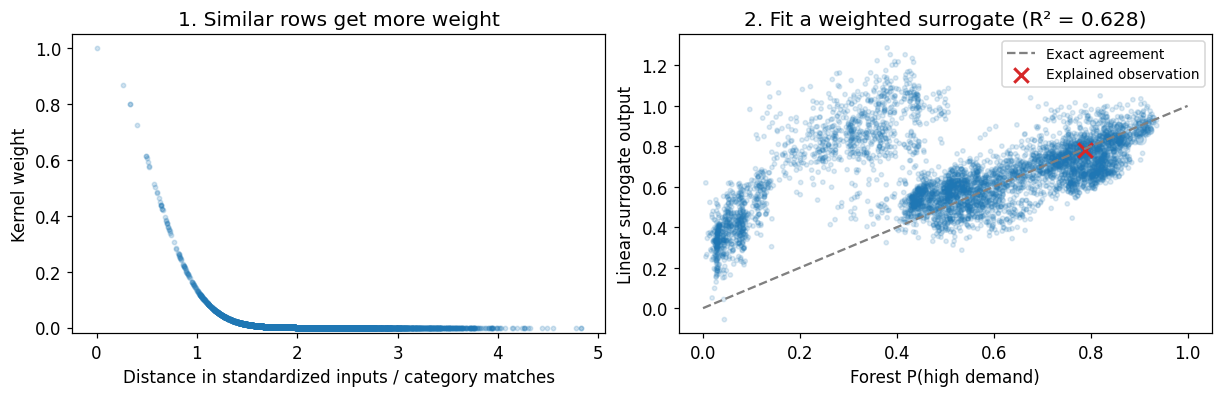

In [16]:
#| echo: false
#| out-height: "360px"
from sklearn.linear_model import Ridge

class RecordedRidge(Ridge):
    def fit(self, X, y, sample_weight=None):
        self.design_ = np.asarray(X).copy()
        self.targets_ = np.asarray(y).copy()
        self.weights_ = np.asarray(sample_weight).copy()
        return super().fit(X, y, sample_weight=sample_weight)

lime_trace_model = RecordedRidge(alpha=1, fit_intercept=True)
lime_trace = explain_lime(x, model_regressor=lime_trace_model)
# Recover full-representation distances from the kernel weights.
lime_trace_distances = np.sqrt(-2 * 0.5**2 * np.log(np.maximum(
    lime_trace_model.weights_, np.finfo(float).tiny)))
lime_trace_predictions = lime_trace_model.predict(lime_trace_model.design_)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), layout="constrained")
axes[0].scatter(lime_trace_distances, lime_trace_model.weights_, s=8, alpha=.2)
axes[0].set(xlabel="Distance in standardized inputs / category matches",
            ylabel="Kernel weight", ylim=(-.02, 1.05), title="1. Similar rows get more weight")
axes[1].scatter(lime_trace_model.targets_, lime_trace_predictions,
    s=8 + 65 * lime_trace_model.weights_, alpha=.15, color="tab:blue")
axes[1].plot([0, 1], [0, 1], color="gray", linestyle="--", label="Exact agreement")
axes[1].scatter(lime_trace_model.targets_[0], lime_trace_predictions[0],
    marker="x", s=90, color="tab:red", linewidths=2, label="Explained observation")
axes[1].set(xlabel="Forest P(high demand)", ylabel="Linear surrogate output",
            title=f"2. Fit a weighted surrogate (R² = {lime_trace.score:.3f})")
axes[1].legend(fontsize=9)
plt.show()


# Read a LIME Explanation

The bars are coefficients of the small local surrogate:

- Positive numeric coefficients mean increasing that standardized input raises the surrogate output; negative coefficients mean it lowers it.
- `workingday=0` describes matching this observation's non-working-day flag.

These are not causal effects.

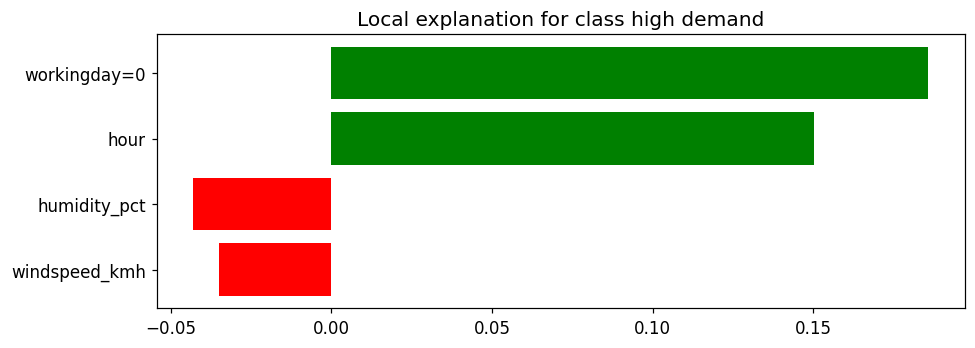

In [17]:
#| echo: false
#| out-height: "350px"
fig = lime_exp.as_pyplot_figure(label=1)
fig.set_size_inches(9, 3.3)
plt.tight_layout()
plt.show()


# Reading This LIME Result

At **14:00 on 5 August 2012**, the forest predicts **78.73%** high-demand probability.

- Use the actual encoded values to read the four terms:

| Term | Coefficient | Encoded value | Contribution |
| --- | ---: | ---: | ---: |
| `workingday` | $+0.186$ | $+1.000$ | $+0.186$ |
| `hour` | $+0.150$ | $+0.354$ | $+0.053$ |
| `humidity_pct` | $-0.043$ | $-1.019$ | $+0.044$ |
| `windspeed_kmh` | $-0.035$ | $+2.146$ | $-0.075$ |

The intercept is **0.577**. Add it to the contributions to obtain the surrogate's **78.43%** prediction.

- A negative humidity coefficient means increasing humidity lowers the local output.


# Does the surrogate fit the forest?

Inspect both diagnostics:

- **Point discrepancy:** surrogate prediction versus forest probability at this hour.
- **Weighted $R^2$:** agreement on LIME's sampled neighborhood.

In [18]:
#| echo: false
def lime_diagnostics(explanation, row):
    probability = float(forest.predict_proba(row)[0, 1])
    surrogate = float(explanation.local_pred[0])
    return {"forest_P(high)": probability, "surrogate_at_hour": surrogate,
            "point_discrepancy": abs(probability - surrogate),
            "weighted_R2": float(explanation.score)}
display(pd.DataFrame([lime_diagnostics(lime_exp, x)]).round(3))


,forest_P(high),surrogate_at_hour,point_discrepancy,weighted_R2
0,0.787,0.784,0.003,0.628


# LIME stability

Repeat the explanation of the **same model and hour** with different random seeds.

- Do the strongest terms and their signs change?
- Do local fit and point discrepancy change?
- Would the explanation support the same operator decision?

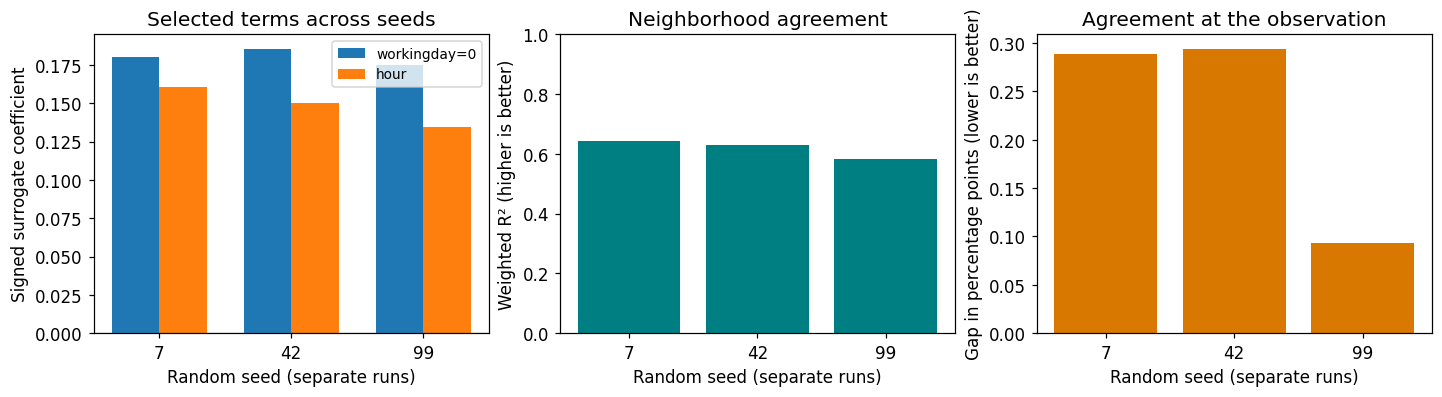

In [19]:
#| echo: false
#| out-height: "360px"
lime_seed_rows = []
lime_seed_explanations = {}
for seed in [7, 42, 99]:
    explanation = explain_lime(x, seed=seed)
    lime_seed_explanations[seed] = explanation
    diagnostics = lime_diagnostics(explanation, x)
    terms = [f"{condition} ({weight:+.2f})"
             for condition, weight in explanation.as_list(label=1)[:2]]
    lime_seed_rows.append({"seed": seed, "weighted_R2": diagnostics["weighted_R2"],
        "point_gap": diagnostics["point_discrepancy"],
        "strongest_term": terms[0], "second_term": terms[1]})
lime_seed_results = pd.DataFrame(lime_seed_rows)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), layout="constrained")
seed_positions = np.arange(len(lime_seed_results))
bar_width = 0.36
for offset, condition in enumerate([c for c, _ in lime_exp.as_list(label=1)[:2]]):
    weights = [dict(lime_seed_explanations[int(seed)].as_list(label=1)).get(condition, np.nan)
               for seed in lime_seed_results.seed]
    axes[0].bar(seed_positions + (offset - 0.5) * bar_width, weights,
                width=bar_width, label=condition)
axes[0].axhline(0, color="gray", linewidth=.8)
axes[0].set(ylabel="Signed surrogate coefficient", title="Selected terms across seeds")
axes[0].legend(fontsize=9)
axes[1].bar(seed_positions, lime_seed_results.weighted_R2, color="#007F82")
axes[1].set(ylabel="Weighted R² (higher is better)", ylim=(0, 1), title="Neighborhood agreement")
axes[2].bar(seed_positions, 100 * lime_seed_results.point_gap, color="#D97800")
axes[2].set(ylabel="Gap in percentage points (lower is better)", title="Agreement at the observation")
for ax in axes:
    ax.set_xticks(seed_positions, lime_seed_results.seed.astype(str))
    ax.set_xlabel("Random seed (separate runs)")
plt.show()


# LIME: Limitations and the Next Question

LIME provides a short local summary, with several limitations [@ribeiro2016should]:

- **Approximation:** a small linear surrogate can miss nonlinear behavior and interactions.
- **Dependence on choices:** sampling, random seed, feature encoding, neighborhood width and explanation length can change the result.
- **Unrealistic perturbations:** sampled combinations may not resemble real bike-sharing observations.
- **Local scope:** good agreement here does not guarantee agreement elsewhere; the coefficients are model associations rather than causal effects.

Can we allocate the model's actual prediction using an explicit rule for sharing credit?

# SHAP

# The Problem: Share a Prediction Difference

LIME gave us a small model that behaves similarly nearby.

> For **14:00 on 5 August 2012**, the forest predicts **78.73%** high-demand probability.
> How do input features contribute to this prediction?

How should we allocate the prediction contribution?

- Problem: features interact.
- The information supplied by temperature can depend on whether hour is already known [@lundberg2017unified].


# Intuition: Reveal Values, Keep the Model Fixed

**The target is the 14:00 observation we want to explain.**

| Row | Hour | Work | Adverse | Temp (°C) | Humidity (%) | Wind (km/h) | P(high) |
| --- | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| **Target** | **14** | **0** | **0** | **34.30** | **42** | **31.00** | **78.73%** |

B1–B3 are the first three of our 100 reference training rows.

| Row | Hour | Work | Adverse | Temp (°C) | Humidity (%) | Wind (km/h) | P(high) |
| --- | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| B1 | 5 | 1 | 0 | 20.20 | 83 | 13.00 | 0.92% |
| B2 | 16 | 1 | 0 | 23.96 | 57 | 11.00 | 81.69% |
| B3 | 12 | 1 | 0 | 32.42 | 44 | 20.00 | 45.83% |


**Nothing revealed:** query the already fitted forest on the reference rows.

- Their 100 prediction probabilities average **31.35%**.
- “Missing” means the target's value is **unrevealed for the explanation**.
    - The model still receives all six columns, filled with original values


# Reveal Hour First: Replace Its Values, Then Predict

To **reveal a feature**, copy its value from the target observation into every reference row.

- “Adding a feature” means copying one more target value into these query rows.
- Leave unrevealed columns at their original values, predict on the resulting rows, and average the probabilities.

| Row | Hour | Work | Adverse | Temp (°C) | Humidity (%) | Wind (km/h) | P(high) |
| --- | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| **Target** | **14** | **0** | **0** | **34.30** | **42** | **31.00** | **78.73%** |

Reveal hour. Fix **hour = 14** in every reference row and Keep its other five values unchanged.

| Row | Hour | Work | Adverse | Temp (°C) | Humidity (%) | Wind (km/h) | P(high) |
| --- | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| B1 | **14** | 1 | 0 | 20.20 | 83 | 13.00 | 57.55% |
| B2 | **14** | 1 | 0 | 23.96 | 57 | 11.00 | 62.27% |
| B3 | **14** | 1 | 0 | 32.42 | 44 | 20.00 | 46.08% |

```python
mixed = background.copy()
mixed["hour"] = x.iloc[0]["hour"]
probabilities = forest.predict_proba(mixed)[:, 1]
```

Across all 100 mixed rows, the mean is **40.59%**, versus **31.35%** with nothing revealed: **+9.24 percentage points**.


# Reveal Temperature First: A Different Context

| Row | Hour | Work | Adverse | Temp (°C) | Humidity (%) | Wind (km/h) | P(high) |
| --- | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| **Target** | **14** | **0** | **0** | **34.30** | **42** | **31.00** | **78.73%** |

Reveal temperature: start again from the original reference rows and fix only **temperature = 34.30°C**.

- Hour is missing, so its reference values remain.

| Row | Hour | Work | Adverse | Temp (°C) | Humidity (%) | Wind (km/h) | P(high) |
| --- | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| B1 | 5 | 1 | 0 | **34.30** | 83 | 13.00 | 3.34% |
| B2 | 16 | 1 | 0 | **34.30** | 57 | 11.00 | 80.12% |
| B3 | 12 | 1 | 0 | **34.30** | 44 | 20.00 | 45.47% |


```python
mixed = background.copy()
mixed["temperature_C"] = x.iloc[0]["temperature_C"]
probabilities = forest.predict_proba(mixed)[:, 1]
```

The same forest (no retraining!) now gives a mean of **39.60%**.

# Reveal Hour and Temperature

| Row | Hour | Work | Adverse | Temp (°C) | Humidity (%) | Wind (km/h) | P(high) |
| --- | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| **Target** | **14** | **0** | **0** | **34.30** | **42** | **31.00** | **78.73%** |

Reveal temperature and hour.

| Row | Hour | Work | Adverse | Temp (°C) | Humidity (%) | Wind (km/h) | P(high) |
| --- | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| B1 | **14** | 1 | 0 | **34.30** | 83 | 13.00 | 47.52% |
| B2 | **14** | 1 | 0 | **34.30** | 57 | 11.00 | 45.66% |
| B3 | **14** | 1 | 0 | **34.30** | 44 | 20.00 | 45.71% |

```python
mixed = background.copy()
mixed[["hour", "temperature_C"]] = x.iloc[0][["hour", "temperature_C"]].to_numpy()
probabilities = forest.predict_proba(mixed)[:, 1]
```

The mean becomes **52.06%**. Adding hour after temperature changes it by **+12.46 points**, compared with **+9.24 points** when hour is revealed first.


# A Worked Example with Real Forest Outputs

**Shapley's idea** is then to average each feature's prediction increment across different reveal orders [@lundberg2017unified].

::::{.columns}
:::{.column width="50%"}
| Values revealed | Mean forest probability |
| --- | ---: |
| None | 31.35% |
| Hour = 14 only | 40.59% |
| Actual temperature only | 39.60% |
| Both | 52.06% |
:::
:::{.column width="50%"}
| Reveal order | Hour's increment | Temperature's increment |
| --- | ---: | ---: |
| Hour, then temperature | +9.24 points | +11.47 points |
| Temperature, then hour | +12.46 points | +8.25 points |
| **Average share** | **+10.85 points** | **+9.86 points** |
:::
::::


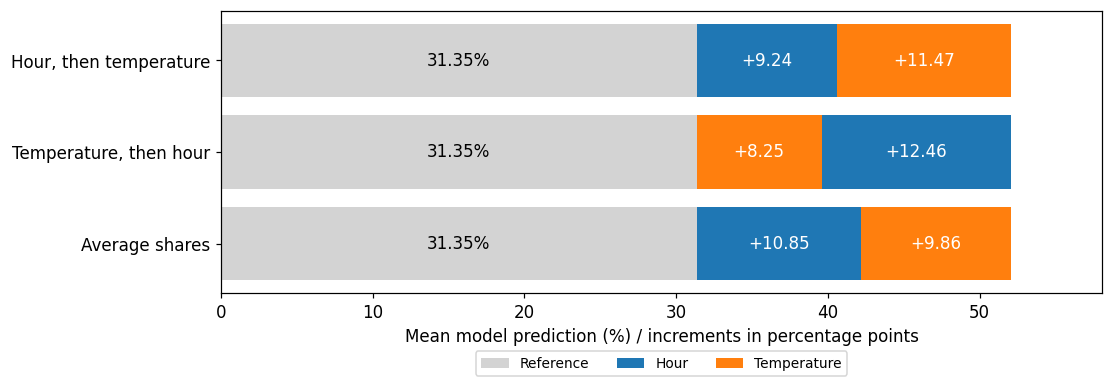

In [20]:
#| echo: false
#| out-height: "360px"
shapley_example_background = X_train.sample(n=min(100, len(X_train)), random_state=RANDOM_STATE)
shapley_example_values = {}
for label, revealed in [("none", []), ("hour", ["hour"]),
                         ("temperature", ["temperature_C"]),
                         ("both", ["hour", "temperature_C"])]:
    mixed = shapley_example_background.copy()
    for name in revealed:
        mixed[name] = x.iloc[0][name]
    shapley_example_values[label] = float(forest.predict_proba(mixed)[:, 1].mean())
q = shapley_example_values
shapley_order_names = ["Hour, then temperature", "Temperature, then hour", "Average shares"]
shapley_order_contributions = np.array([
    [q["hour"]-q["none"], q["both"]-q["hour"]],
    [q["both"]-q["temperature"], q["temperature"]-q["none"]]])
shapley_order_contributions = np.vstack([
    shapley_order_contributions, shapley_order_contributions.mean(axis=0)])
fig, ax = plt.subplots(figsize=(10, 3.4), layout="constrained")
for row, contributions in enumerate(shapley_order_contributions):
    ax.barh(row, 100*q["none"], color="lightgray", label="Reference" if row==0 else None)
    left = 100*q["none"]
    for feature in ([1, 0] if row==1 else [0, 1]):
        value = 100*contributions[feature]
        ax.barh(row, value, left=left, color=["tab:blue", "tab:orange"][feature],
            label=["Hour", "Temperature"][feature] if row==0 else None)
        ax.text(left+value/2, row, f"{value:+.2f}", ha="center", va="center", color="white")
        left += value
    ax.text(50*q["none"], row, f'{100*q["none"]:.2f}%', ha="center", va="center")
ax.set(yticks=range(3), yticklabels=shapley_order_names, xlim=(0, 100*q["both"]+6),
       xlabel="Mean model prediction (%) / increments in percentage points")
ax.invert_yaxis()
ax.legend(loc="upper center", bbox_to_anchor=(.5, -.18), ncol=3, fontsize=9)
plt.show()


# Formalize a Partly Revealed Observation

$$v_x(S)=\frac{1}{|B|}\sum_{z\in B}f(x_S,z_{\bar S}).$$

| Symbol | Meaning |
| --- | --- |
| $x$, $f$ | The chosen observation and the fixed forest's high-demand probability function |
| $F$, $S\subseteq F$ | All input features, and the subset whose values have been revealed |
| $B$, $z$, $|B|$ | The 100 reference training rows, one such row, and the number of rows |
| $x_S$ | This observation's values for the revealed features |
| $\bar S=F\setminus S$, $z_{\bar S}$ | Unrevealed features, filled using values from reference row $z$ |
| $v_x(S)$ | Average forest prediction for these mixed rows |

**Only the query inputs change; the function $f$ and its learned parameters stay fixed.**

- $v_x(\varnothing)$ is the reference mean and $v_x(F)=f(x)$ is the actual prediction.


# Compute Each Feature's Share

For feature $j$ among $p=|F|$ features:

$$\phi_j(x)=\sum_{S\subseteq F\setminus\{j\}}\frac{|S|!(p-|S|-1)!}{p!}\left[v_x(S\cup\{j\})-v_x(S)\right].$$

- $S$ contains features revealed **before** $j$; $S\cup\{j\}$ fixes one more input column to the target value; the model itself is unchanged.
- $|S|$ counts features in $S$;
- The weight is the fraction of feature orders in which exactly $S$ precedes $j$.
- Summing these weighted changes gives $\phi_j(x)$: feature $j$'s average share across reveal orders.

The reference and contributions reconstruct the prediction: $\underbrace{\phi_0}_{v_x(\varnothing)}+\sum_{j\in F}\phi_j(x)=f(x).$

Here $\phi_0$ is the reference probability, and signed $\phi_j$ values are in probability units [@lundberg2017unified].


# The Algorithm: Average Reveal Increments

1. Choose a feature order and start with the reference prediction.
2. Reveal features one at a time, recording each change in the model's prediction.
3. Credit each change to the feature just revealed.
4. Repeat for other orders, then average each feature's credits.

```text
For each feature order:
    revealed = empty set
    previous = prediction with no features revealed
    For feature j in that order:
        current = prediction after also revealing j
        credit[j] += current - previous
        add j to revealed; previous = current
Divide each feature's credit by the number of orders used.
```

All orders give exact Shapley values.

- With six features, there are 720 orders but only **64 distinct revealed subsets**, whose predictions can be cached [@lundberg2017unified].


# Computing the Shares Efficiently

| Method | How it computes the same kind of allocation | Model access |
| --- | --- | --- |
| Feature-order estimator | Average prediction increments over sampled orders | Query predictions |
| KernelSHAP | Sample revealed subsets and fit a specially weighted additive regression | Query predictions |
| TreeSHAP | Use tree structure to compute contributions efficiently | Inspect tree paths |

Listing every order is expensive. **Our forest is a tree ensemble, so we use TreeSHAP** [@lundberg2017unified; @lundberg2020local].

# TreeSHAP [@lundberg2020local]: Many Subsets Share a Path Outcome

![Tree path and revealed subsets with the same leaf outcome](https://github.com/w4bo/AA2627-unibo-dcai/blob/main/slides/img/explainability/treeshap-subset-reuse.png?raw=1){height=430px}

# How TreeSHAP Works

TreeSHAP computes the feature shares defined earlier by exploiting the **already trained tree structure** [@lundberg2020local].

1. **Read the trees:** use their split features, thresholds and leaf outputs.
2. **Account for revealed and unrevealed values:** a revealed split feature uses the target's value; an unrevealed one uses a reference row's value.
3. **Combine many subsets at once:** a leaf depends only on the features tested along its root-to-leaf path
    - Many revealed subsets therefore have the same effect on reaching that leaf.
    - TreeSHAP uses dynamic programming to accumulate their combined Shapley weights instead of evaluating each subset separately.
4. **Combine the results:** average over the reference rows and combine the trees' contributions using the forest's averaging rule.

The **baseline prediction** is the same forest's mean prediction on the reference rows: **31.35%** here.

- TreeSHAP returns contributions satisfying **baseline + feature shares = target prediction**: here **78.73%**.
- It computes this allocation directly from the trees rather than fitting a local surrogate [@lundberg2017unified].


# Apply TreeSHAP to the Bike Forest

Explain the **same 14:00 observation**

1. Choose 100 training observations as the reference.
2. Use this observation's known values for revealed inputs and reference rows for unrevealed ones.
3. Ask TreeSHAP for contributions to **class 1: high-demand probability**.

```python
shap.TreeExplainer(
    forest, data=background,
    feature_perturbation="interventional",
    model_output="probability",
)
```

In [21]:
#| echo: false
background = X_train.sample(n=min(100, len(X_train)), random_state=RANDOM_STATE)
shap_explainer = shap.TreeExplainer(forest, data=background,
    feature_perturbation="interventional", model_output="probability")

def explain_shap(rows, explainer=None):
    explainer = shap_explainer if explainer is None else explainer
    all_classes = explainer(rows)
    high_index = int(np.flatnonzero(forest.classes_ == 1)[0])
    high = all_classes[:, :, high_index]
    assert high.values.shape == (len(rows), len(feature_names))
    return high

shap_high = explain_shap(x)


# Understanding the contributions

> Start from the reference probability **31.35%**.
>
> Hour and temperature contribute the largest upward shares. Non-working-day status and low humidity also raise this prediction relative to the reference; windspeed contributes a small downward share.
>
> The contributions sum to **47.38 points**. Adding the **31.35%** reference gives the actual **78.73%** forest probability.

Positive contributions raise the prediction relative to the reference; negative contributions lower it.


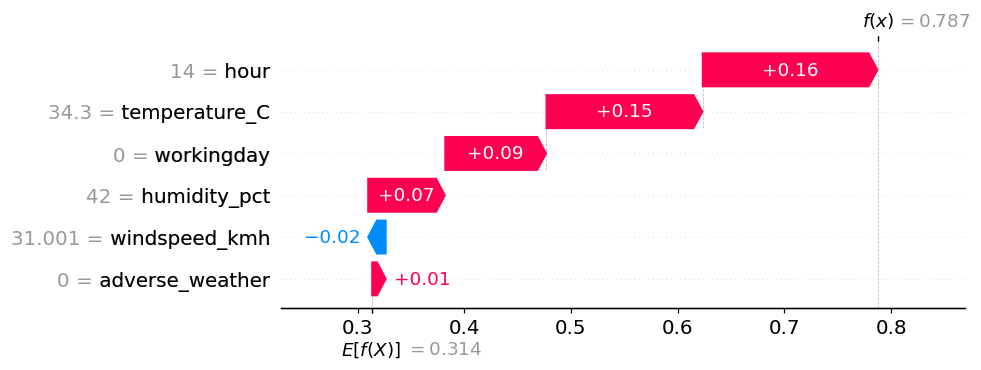

,base,sum_contributions,reconstructed,forest_P(high)
0,0.3135,0.4738,0.7873,0.7873


In [22]:
#| echo: false
#| out-height: "370px"
shap.plots.waterfall(shap_high[0], max_display=len(feature_names), show=False)
plt.gcf().set_size_inches(9, 3.5)
plt.tight_layout()
plt.show()
display(pd.DataFrame([{"base": float(shap_high.base_values[0]),
    "sum_contributions": float(shap_high.values[0].sum()),
    "reconstructed": float(shap_high.base_values[0] + shap_high.values[0].sum()),
    "forest_P(high)": float(forest.predict_proba(x)[0, 1])}]).round(4))


# Making SHAP Computation Practical

Explicitly evaluating all $2^p$ revealed subsets works for our six features (**64 subsets**), but 30 features already imply over **one billion** subsets.

| Optimization | Practical implication |
| --- | --- |
| **Use model structure** | TreeSHAP exploits trained tree paths instead of explicitly listing every subset [@lundberg2020local]. |
| **Use a reference sample** | Our 100 training rows represent the background. Interventional TreeSHAP runtime grows linearly with reference size. |
| **Explain selected observations** | Inspect individual cases or a representative sample for global summaries, rather than automatically explaining every row. |
| **For black-box models, sample** | Sample feature orders or use KernelSHAP instead of exhaustive enumeration; check estimates as the evaluation budget increases [@lundberg2017unified]. |

The main costs are the number of observations explained, reference size, and model complexity.

{{< include _coding_break2.qmd >}}


# SHAP: From One Prediction to Global Model Interpretation

<a id="theory-block-3"></a>

**Local question:** why does this observation differ from the reference?

**Global question:** which inputs move predictions most across many observations?


In [23]:
#| echo: false
#| output: false
explain_rows = X_valid.sample(n=60, random_state=RANDOM_STATE)
shap_batch = explain_shap(explain_rows)
mean_abs = pd.Series(np.abs(shap_batch.values).mean(axis=0), index=feature_names).sort_values()
feature_order = [feature_names.index(name) for name in mean_abs.index]


# SHAP Beeswarm: Direction, Magnitude, and Variation

Start with the distribution of local contributions across the sampled observations [@lundberg2020local].

- Features are ordered by mean absolute SHAP value.
- **Each dot:** one validation observation for that feature.
- **Horizontal position:** its signed SHAP contribution. Right raises high-demand probability relative to the reference; left lowers it. A value of $+0.1$ means **+10 percentage points**.
- **Vertical spread:** dots stack to show density; it is not another feature value.

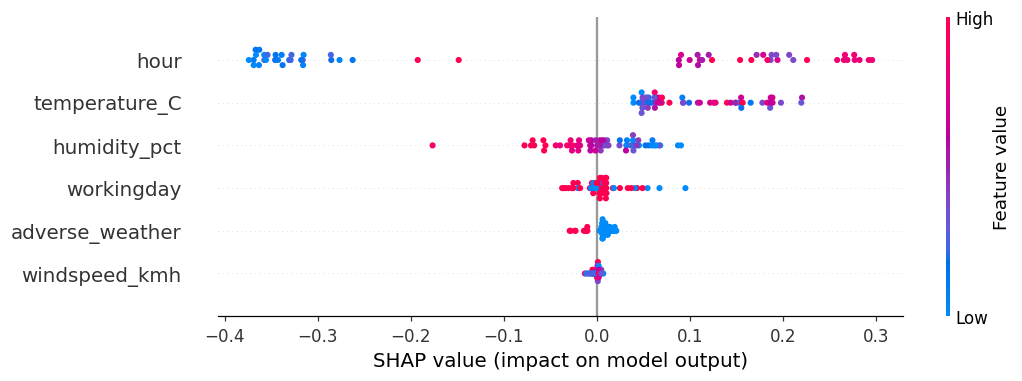

In [24]:
#| echo: false
#| out-height: "360px"
shap.plots.beeswarm(shap_batch, max_display=len(feature_names), show=False, plot_size=(10, 3.6))
plt.tight_layout()
plt.show()


# SHAP: From One Prediction to Global Model Interpretation

Explain **$n$ sampled rows**, using the same fitted forest, and 100 reference training rows.

$$I_j=\frac{1}{n}\sum_{i=1}^{n}|\phi_j(x_i)|.$$

- $x_i$ is explained observation, $\phi_j(x_i)$ is feature $j$'s signed contribution, and $I_j$ measures its **average contribution magnitude** [@lundberg2020local].

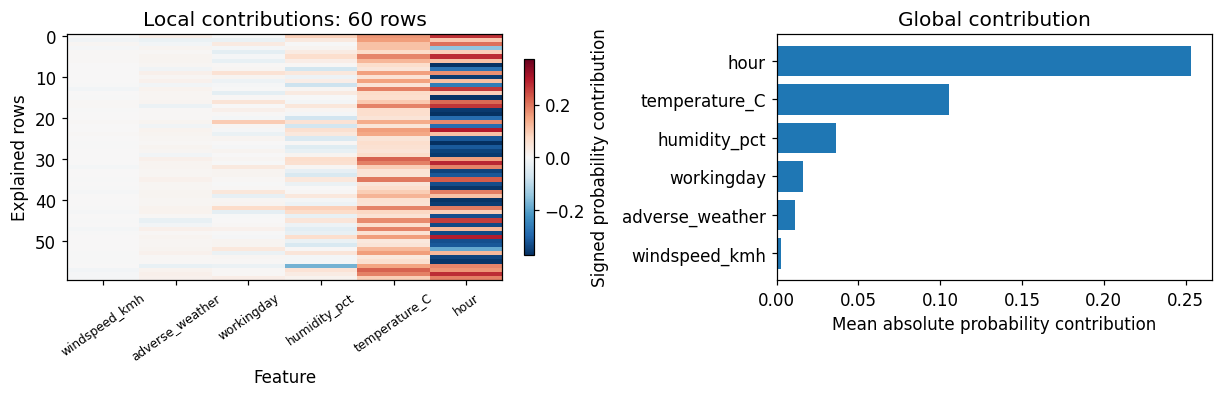

In [25]:
#| echo: false
#| out-height: "360px"
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), layout="constrained")
limit = np.abs(shap_batch.values).max()
heat = axes[0].imshow(shap_batch.values[:, feature_order], aspect="auto", cmap="RdBu_r", vmin=-limit, vmax=limit)
axes[0].set(xticks=range(len(feature_order)), xticklabels=mean_abs.index,
            xlabel="Feature", ylabel="Explained rows", title="Local contributions: 60 rows")
axes[0].tick_params(axis="x", labelrotation=35, labelsize=8)
fig.colorbar(heat, ax=axes[0], label="Signed probability contribution", shrink=.8)
axes[1].barh(mean_abs.index, mean_abs, color="tab:blue")
axes[1].set(xlabel="Mean absolute probability contribution", title="Global contribution")
plt.show()


For these **60 validation observations**: *hour* dominates and its contributions vary widely and can raise or lower predictions.

:::{.fragment}
*These are not causal effects*.
:::

# No single scalar certifies interpretability.

| Quantity | Scope and question | Units |
| --- | --- | --- |
| Logistic coefficient | How sensitive is fitted log-odds to this encoded input? | Log-odds per input unit |
| LIME coefficient | Which conditions support a local surrogate? | Surrogate output units |
| Local TreeSHAP value | How is one prediction minus its baseline allocated? | Here: probability |
| Mean absolute TreeSHAP | Which features move predictions most across these hours? | Here: probability |

# Dependence and unrealistic combinations

We want to know whether a conclusion is supported by the model, by a particular comparison population, or by sampling variability.

> Imagine holding hour and working-day status fixed while borrowing weather from unrelated hours.
>
> - The resulting row may be uncommon or implausible.
> - A predictor can behave unexpectedly away from its training distribution.

# Reference Sensitivity: What Are We Comparing Against?

Keep the **same forest and the same afternoon observation**, but change the SHAP reference:

- **All training hours:** why does this prediction differ from a typical hour in the training reference?
- **Training morning hours (7–9):** why does it differ from a typical morning in that reference?

The reference mean and feature shares can change because **we changed the comparison question**.

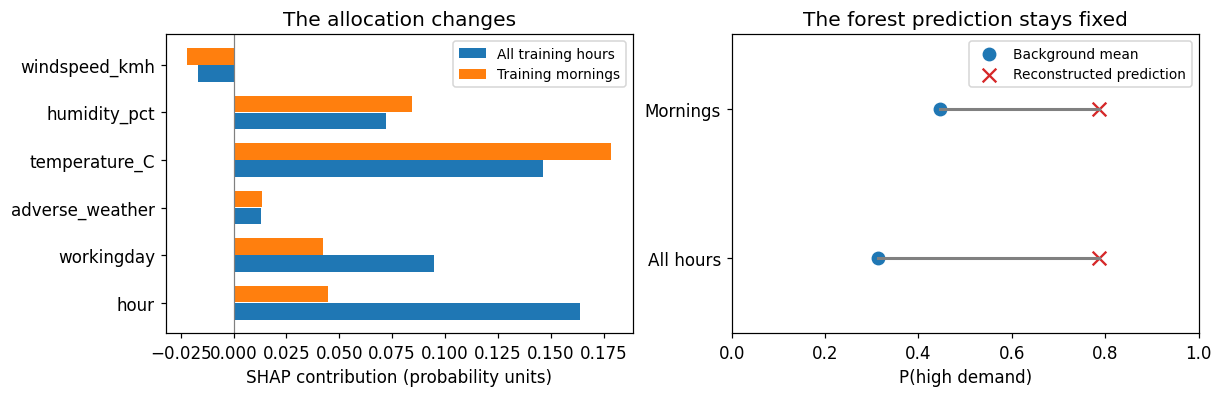

In [26]:
#| echo: false
#| out-height: "360px"
morning_pool = X_train.loc[X_train.hour.between(7, 9)]
morning_background = morning_pool.sample(n=min(100, len(morning_pool)), random_state=RANDOM_STATE)
morning_explainer = shap.TreeExplainer(forest, data=morning_background,
    feature_perturbation="interventional", model_output="probability")
shap_morning = explain_shap(x, morning_explainer)
background_comparison = pd.DataFrame({
    "all_hours": shap_high.values[0], "morning_hours": shap_morning.values[0],
}, index=feature_names)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), layout="constrained")
positions = np.arange(len(feature_names))
axes[0].barh(positions - .18, background_comparison.all_hours, height=.35, label="All training hours")
axes[0].barh(positions + .18, background_comparison.morning_hours, height=.35, label="Training mornings")
axes[0].axvline(0, color="gray", linewidth=.8)
axes[0].set(yticks=positions, yticklabels=feature_names, xlabel="SHAP contribution (probability units)",
            title="The allocation changes")
axes[0].legend(fontsize=9)
background_bases = [float(shap_high.base_values[0]), float(shap_morning.base_values[0])]
fixed_probability = float(forest.predict_proba(x)[0, 1])
for position, base in enumerate(background_bases):
    axes[1].plot([base, fixed_probability], [position, position], color="gray", linewidth=2)
axes[1].scatter(background_bases, [0, 1], s=65, color="tab:blue", label="Background mean")
axes[1].scatter([fixed_probability] * 2, [0, 1], marker="x", s=80, color="tab:red", label="Reconstructed prediction")
axes[1].set(yticks=[0, 1], yticklabels=["All hours", "Mornings"], ylim=(-.5, 1.5), xlim=(0, 1),
            xlabel="P(high demand)", title="The forest prediction stays fixed")
axes[1].legend(fontsize=9, loc="upper right")
plt.show()


# Recall Lab 04: Accuracy vs Model Simplicity

Reuse the multi-objective idea from the fairness lab, now for candidate **decision trees**:

$$\min_h\left(1-\mathrm{BA}_{\mathrm{valid}}(h),\;\#\mathrm{leaves}(h)\right).$$

- **Prediction objective:** lower validation error, where $\mathrm{BA}$ is balanced accuracy.
- **Complexity objective:** fewer leaves to inspect; this is a readability proxy, not a human evaluation.

**Question:** how much predictive performance would you exchange for a smaller tree?


In [27]:
#| echo: false
tree_candidates = {}
rows = []
for depth in [1, 2, 3, 4, 6, 8]:
    candidate = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=40,
        random_state=RANDOM_STATE).fit(X_train, y_train)
    tree_candidates[depth] = candidate
    rows.append({"max_depth": depth, "leaves": candidate.get_n_leaves(),
                 **evaluate(candidate, X_valid, y_valid)})
tradeoffs = pd.DataFrame(rows)
tradeoffs["error"] = 1 - tradeoffs.balanced_accuracy

def pareto_mask(costs):
    costs = np.asarray(costs, dtype=float)
    return np.array([not np.any(np.all(costs <= point, axis=1)
        & np.any(costs < point, axis=1)) for point in costs])

tradeoffs["pareto"] = pareto_mask(tradeoffs[["error", "leaves"]])


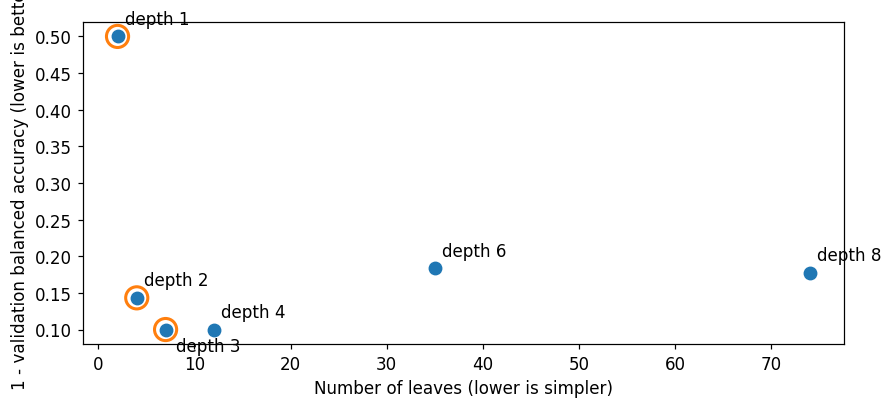

In [28]:
#| echo: false
#| out-height: "370px"
fig, ax = plt.subplots(figsize=(8, 3.6), layout="constrained")
ax.scatter(tradeoffs.leaves, tradeoffs.error, s=65)
front = tradeoffs.loc[tradeoffs.pareto]
ax.scatter(front.leaves, front.error, s=210, facecolors="none", edgecolors="tab:orange", linewidths=2)
for row in tradeoffs.itertuples():
    offset = (7, -14) if row.max_depth == 3 else (5, 8)
    ax.annotate(f"depth {row.max_depth}", (row.leaves, row.error), xytext=offset, textcoords="offset points")
ax.set(xlabel="Number of leaves (lower is simpler)",
       ylabel="1 - validation balanced accuracy (lower is better)")
plt.show()


# Neural Networks: What Can We Inspect?

A neural network combines learned transformations, for example:

$$F(x)=\sigma\!\left(W_2\,\mathrm{ReLU}(W_1z(x)+b_1)+b_2\right).$$

| Structural proxy | What it counts | Limitation |
| --- | --- | --- |
| Trainable parameters | Weights and biases | Does not reveal which inputs drive a prediction |
| Depth and width | Layers and hidden units | Small networks can still be difficult to understand |
| Nonzero parameters | Connections remaining after sparsification | Sparse weights do not guarantee meaningful hidden features |

Use these as **complexity proxies**.


# Neural Networks: Simple Prediction Explanations

Keep the trained network fixed and explain a chosen output $F(x)$, such as the predicted probability of high bike demand.

| Method | Question | Scope |
| --- | --- | --- |
| Permutation importance | How much does validation performance drop when an input is shuffled? | Global, score-dependent |
| Input gradients | Which numeric inputs affect this output under tiny changes? | Local sensitivity [@simonyan2013deep] |
| Integrated Gradients | How is the output difference from a chosen baseline allocated to inputs? | Local attribution [@sundararajan2017axiomatic] |


{{< include _coding_break3.qmd >}}


# Exercises: Short Guided Tasks

Run the setup and theory cells first. Use `exercise_x` (validation position 854), `reference_probability`, and `exercise_shap`.

| Provided | What it does |
| --- | --- |
| `evaluate(model, X_valid, y_valid)` | Reports validation scores |
| `tree_path_table(model, row)` | Lists the split conditions followed by one observation |
| `explain_lime`, `lime_diagnostics`, `lime_seed_results` | Produce/read a local explanation and its seed comparison |
| `explain_shap`, `shap_batch` | Produce a local explanation or reuse the 60-row global explanation |
| `background`, `morning_explainer` | Supply the two reference comparisons |

In [29]:
#| echo: false
#| output: false
# Select the validation observation and define the tree-path helper.
exercise_x = X_valid.iloc[[854]]

def tree_path_table(model, row):
    records = []
    for node in model.decision_path(row).indices:
        feature = model.tree_.feature[node]
        if feature >= 0:
            threshold = model.tree_.threshold[node]
            value = row.iloc[0, feature]
            records.append({"feature": row.columns[feature], "value": value,
                            "condition": f"{'<=' if value <= threshold else '>'} {threshold:.2f}"})
    return pd.DataFrame(records)


# Exercise 1: Is a Deeper Tree Worth It?

<a id="coding-exercises-1"></a>
<a id="exercise-1"></a>

Fit a depth-4 tree by filling the template.

- Compare validation balanced accuracy and recall with the existing models.
- Compare the depth-2 and depth-4 trees' leaf counts.
- **Discuss:** is the measured gain worth the larger tree? Use the existing structural-complexity slide for the logistic model.


In [37]:
student_tree = DecisionTreeClassifier(
    max_depth=4, min_samples_leaf=40, random_state=RANDOM_STATE,  # Hint: use depth 4.
).fit(X_train, y_train)
display(pd.DataFrame({
    "Logistic": evaluate(logistic, X_valid, y_valid),
    "Tree depth 2": evaluate(small_tree, X_valid, y_valid),
    "Tree depth 4": evaluate(student_tree, X_valid, y_valid),  # Hint: the tree you just fitted.
}).T.round(3))
print("Leaves (depth 2 / depth 4):", small_tree.get_n_leaves(), student_tree.get_n_leaves())  # Hint: call get_n_leaves on your tree.


,balanced_accuracy,high_demand_recall
Logistic,0.883,0.869
Tree depth 2,0.857,0.995
Tree depth 4,0.900,0.947


Leaves (depth 2 / depth 4): 4 12


In [40]:
from sklearn.tree import export_text

print("\n=== Decision Tree (Depth 2) ===")
print(export_text(small_tree, feature_names=list(X_train.columns), decimals=3))

print("\n=== Decision Tree (Depth 4) ===")
print(export_text(student_tree, feature_names=list(X_train.columns), decimals=3))


=== Decision Tree (Depth 2) ===
|--- hour <= 6.500
|   |--- humidity_pct <= 53.500
|   |   |--- class: 0
|   |--- humidity_pct >  53.500
|   |   |--- class: 0
|--- hour >  6.500
|   |--- temperature_C <= 11.270
|   |   |--- class: 0
|   |--- temperature_C >  11.270
|   |   |--- class: 1


=== Decision Tree (Depth 4) ===
|--- hour <= 6.500
|   |--- humidity_pct <= 53.500
|   |   |--- temperature_C <= 18.790
|   |   |   |--- class: 0
|   |   |--- temperature_C >  18.790
|   |   |   |--- temperature_C <= 22.550
|   |   |   |   |--- class: 0
|   |   |   |--- temperature_C >  22.550
|   |   |   |   |--- class: 0
|   |--- humidity_pct >  53.500
|   |   |--- class: 0
|--- hour >  6.500
|   |--- temperature_C <= 11.270
|   |   |--- hour <= 19.500
|   |   |   |--- temperature_C <= 4.690
|   |   |   |   |--- class: 0
|   |   |   |--- temperature_C >  4.690
|   |   |   |   |--- class: 0
|   |   |--- hour >  19.500
|   |   |   |--- hour <= 20.500
|   |   |   |   |--- class: 0
|   |   |   |--- hou

# Exercise 2: Reproduce One Prediction

<a id="exercise-2"></a>

Use `exercise_x` and complete the score calculation.

1. Multiply encoded inputs by logistic coefficients, add the intercept, then apply sigmoid.
2. Compare your probability with `predict_proba`.
3. Call `tree_path_table` to inspect your depth-4 tree's route.

**Discuss:** which prediction is easier to reproduce by hand? Why do score terms not represent fixed probability increments?


In [38]:
student_z = logistic["preprocess"].transform(exercise_x)[0]
student_terms = student_z * logistic["model"].coef_[0]  # Hint: multiply the encoded input values by coefficients.
student_score = logistic["model"].intercept_[0] + student_terms.sum()  # Hint: sum the terms.
student_probability = 1 / (1 + np.exp(-student_score))  # Hint: apply sigmoid to the complete score.
print("Calculated / model probability:", student_probability, logistic.predict_proba(exercise_x)[0, 1])
display(tree_path_table(student_tree, exercise_x))  # Provided helper; no loop to write.


Calculated / model probability: 0.8122623804860586 0.8122623804860586


,feature,value,condition
0,hour,14.0,> 6.50
1,temperature_C,34.3,> 11.27
2,hour,14.0,<= 21.50
3,hour,14.0,<= 15.50


# Coding Session 1: Short Solution {.scrollable}

<details>
<summary>Show the solution</summary>

```python
# Exercise 1: only the new depth-4 tree is trained.
student_tree = DecisionTreeClassifier(
    max_depth=4, min_samples_leaf=40, random_state=RANDOM_STATE,
).fit(X_train, y_train)
display(pd.DataFrame({
    "Logistic": evaluate(logistic, X_valid, y_valid),
    "Tree depth 2": evaluate(small_tree, X_valid, y_valid),
    "Tree depth 4": evaluate(student_tree, X_valid, y_valid),
}).T.round(3))
print("Leaves (depth 2 / depth 4):", small_tree.get_n_leaves(), student_tree.get_n_leaves())

# Exercise 2: sum score terms, convert once, then read the provided tree path.
student_z = logistic["preprocess"].transform(exercise_x)[0]
student_terms = student_z * logistic["model"].coef_[0]
student_score = logistic["model"].intercept_[0] + student_terms.sum()
student_probability = 1 / (1 + np.exp(-student_score))
print("Calculated / model probability:", student_probability, logistic.predict_proba(exercise_x)[0, 1])
display(tree_path_table(student_tree, exercise_x))
```

</details>


In [32]:
#| echo: false
#| output: false
# Provided for coding session 2, after the local-explanation theory.
reference_probability = float(forest.predict_proba(background)[:, 1].mean())
exercise_shap = explain_shap(exercise_x)


# Exercise 3: Read and Check LIME

<a id="coding-exercises-2"></a>
<a id="exercise-3"></a>

Explain `exercise_x` and compare the seed results.

- Identify the strongest positive and negative coefficients.
- Read weighted $R^2$ and the point prediction gap from `lime_diagnostics`.
- Use the existing `lime_seed_results` table: do the runs tell a similar story?

Distinguish numeric slopes from categorical matches.


In [45]:
student_lime = explain_lime(exercise_x, seed=42, num_features=4, num_samples=5000)  # Hint: explain exercise_x.
display(pd.DataFrame(student_lime.as_list(label=1), columns=["term", "coefficient"]))
display(pd.DataFrame([lime_diagnostics(student_lime, exercise_x)]).round(3))  # Hint: pass your explanation.
display(lime_seed_results[["seed", "weighted_R2", "point_gap"]].round(3))  # Already computed in the lesson.


,term,coefficient
0,workingday=0,0.185663
1,hour,0.150320
2,humidity_pct,-0.042996
3,windspeed_kmh,-0.035095


,forest_P(high),surrogate_at_hour,point_discrepancy,weighted_R2
0,0.787,0.784,0.003,0.628


,seed,weighted_R2,point_gap
0,7,0.644,0.003
1,42,0.628,0.003
2,99,0.582,0.001


# Exercise 4: Reveal Hour and Read SHAP

<a id="exercise-4"></a>

`reference_probability` is the forest's average prediction on `background`.

1. In a copy of the background, fix the hour column to `exercise_x`'s hour and compute the mean prediction change.
2. Explain the target with SHAP using `explain_shap` and the waterfall call.
3. Add the baseline and signed contributions; compare the result with the forest probability.

**Discuss:** why can the first-reveal hour increment differ from the full SHAP hour contribution? All six columns remain present; the forest is not retrained.


Hour-first increment: 0.09238050690845057


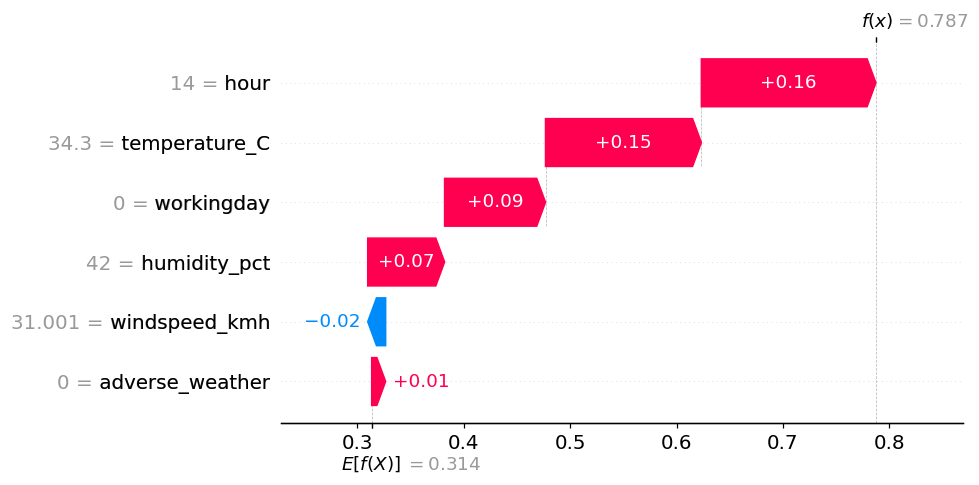

SHAP sum / forest: [0.78727635] [0.78727634]


In [42]:
student_mixed = background.copy()
student_mixed["hour"] = exercise_x.iloc[0]["hour"]  # Hint: exercise_x.iloc[0]["hour"] is copied into EVERY row.
student_revealed = forest.predict_proba(student_mixed)[:, 1].mean()
print("Hour-first increment:", student_revealed - reference_probability)
student_shap = explain_shap(exercise_x)
shap.plots.waterfall(student_shap[0], max_display=len(feature_names))
student_reconstructed = student_shap.base_values + student_shap.values.sum(axis=1)  # Hint: sum across features.
print("SHAP sum / forest:", student_reconstructed, forest.predict_proba(exercise_x)[:, 1])


# Coding Session 2: Short Solution {.scrollable}

<details>
<summary>Show the solution</summary>

```python
# Exercise 3: reuse the seed results; spend time interpreting the fit.
student_lime = explain_lime(exercise_x, seed=42)
display(pd.DataFrame(student_lime.as_list(label=1), columns=["term", "coefficient"]))
display(pd.DataFrame([lime_diagnostics(student_lime, exercise_x)]).round(3))
display(lime_seed_results[["seed", "weighted_R2", "point_gap"]].round(3))

# Exercise 4: replace input values, predict, and reconstruct the target probability.
student_mixed = background.copy()
student_mixed["hour"] = exercise_x.iloc[0]["hour"]
student_revealed = forest.predict_proba(student_mixed)[:, 1].mean()
print("Hour-first increment:", student_revealed - reference_probability)
student_shap = explain_shap(exercise_x)
shap.plots.waterfall(student_shap[0], max_display=len(feature_names))
student_reconstructed = student_shap.base_values + student_shap.values.sum(axis=1)
print("SHAP sum / forest:", student_reconstructed, forest.predict_proba(exercise_x)[:, 1])
```
</details>


# Exercise 5: Read the Global SHAP Summary

<a id="coding-exercises-3"></a>
<a id="exercise-5"></a>

Reuse `shap_batch`, which explains 60 validation observations.

1. Compute the mean absolute contribution for each feature; display the ranking in percentage points.
2. Run the beeswarm call. Explain what its dots, horizontal positions, colors, and vertical stacking mean.
3. Name the most influential feature globally and one visible feature-value pattern.

Explain why this population summary may differ from one local explanation.


,0
hour,25.337193
temperature_C,10.513063
humidity_pct,3.632255
workingday,1.600948
adverse_weather,1.114569
windspeed_kmh,0.271965


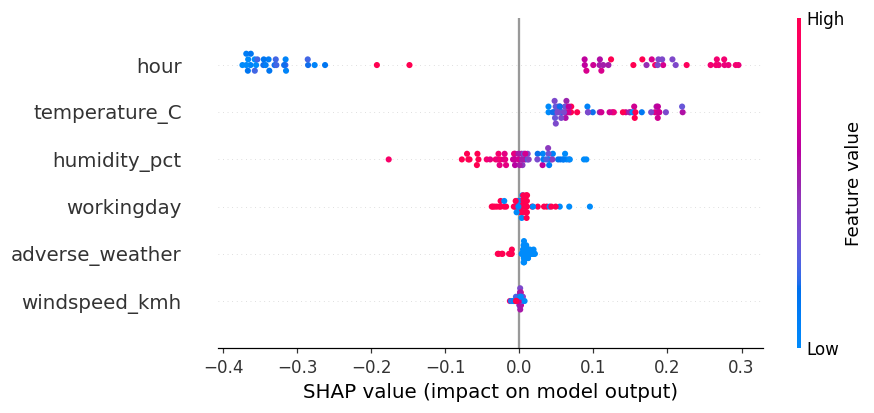

In [46]:
student_importance = pd.Series(
    np.abs(shap_batch.values).mean(axis=0), index=feature_names)  # Hint: average observations, leaving one value per feature.
display((100 * student_importance).sort_values(ascending=False))  # Probability units -> percentage points.
shap.plots.beeswarm(shap_batch, max_display=len(feature_names))


# Exercise 6: Explain the Choice of Reference

<a id="exercise-6"></a>

`exercise_shap` uses all training hours as its reference. Explain the same observation using `morning_explainer` instead.

- Compare the baselines and the table of feature shares.
- Reconstruct both predictions. They should match the same forest probability.
- **Discuss:** which reference answers an afternoon-versus-morning question? Give a two-sentence recommendation and one limitation.

Only the reference changes.


In [47]:
student_morning = explain_shap(exercise_x, morning_explainer)  # Hint: use morning_explainer.
print("Baselines:", exercise_shap.base_values, student_morning.base_values)
display(pd.DataFrame({
    "All hours": exercise_shap.values[0],
    "Mornings": student_morning.values[0],
}, index=feature_names))
print("All-hours sum:", exercise_shap.base_values + exercise_shap.values.sum(axis=1))
print("Morning sum:", student_morning.base_values + student_morning.values.sum(axis=1))  # Hint: use this explanation's own baseline.
print("Forest:", forest.predict_proba(exercise_x)[:, 1])


Baselines: [0.31350693] [0.44594237]


,All hours,Mornings
hour,0.164006,0.044540
workingday,0.094824,0.042129
adverse_weather,0.013093,0.013382
temperature_C,0.146440,0.178732
humidity_pct,0.072244,0.084607
windspeed_kmh,-0.016837,-0.022056


All-hours sum: [0.78727635]
Morning sum: [0.78727634]
Forest: [0.78727634]


# Coding Session 3: Short Solution {.scrollable}

<details>
<summary>Show the solution</summary>

```python
# Exercise 5: aggregate existing values and use the supplied plot.
student_importance = pd.Series(
    np.abs(shap_batch.values).mean(axis=0), index=feature_names)
display((100 * student_importance).sort_values(ascending=False))
shap.plots.beeswarm(shap_batch, max_display=len(feature_names))

# Exercise 6: change the reference, keeping the target and model fixed.
student_morning = explain_shap(exercise_x, morning_explainer)
print("Baselines:", exercise_shap.base_values, student_morning.base_values)
display(pd.DataFrame({
    "All hours": exercise_shap.values[0],
    "Mornings": student_morning.values[0],
}, index=feature_names))
print("All-hours sum:", exercise_shap.base_values + exercise_shap.values.sum(axis=1))
print("Morning sum:", student_morning.base_values + student_morning.values.sum(axis=1))
print("Forest:", forest.predict_proba(exercise_x)[:, 1])
```

The mean absolute ranking summarizes magnitudes across observations; the beeswarm also shows direction and input values. Different references define different comparisons but reconstruct the same prediction. For an afternoon-versus-morning question, use the morning reference and state that the result describes model behavior, not a causal effect of changing the hour.

</details>


# Further reading {.scrollable}

Molnar, *Interpretable Machine Learning*, online third edition:

- [Interpretability](https://christophm.github.io/interpretable-ml-book/interpretability.html), [goals](https://christophm.github.io/interpretable-ml-book/goals.html), [methods overview](https://christophm.github.io/interpretable-ml-book/overview.html)
- [Logistic regression](https://christophm.github.io/interpretable-ml-book/logistic.html), [decision trees](https://christophm.github.io/interpretable-ml-book/tree.html)
- [LIME](https://christophm.github.io/interpretable-ml-book/lime.html), [Shapley values](https://christophm.github.io/interpretable-ml-book/shapley.html), [SHAP](https://christophm.github.io/interpretable-ml-book/shap.html)

Interpretability evaluation and complexity measures:

- Lipton, *The Mythos of Model Interpretability*: model size versus per-prediction computation [@lipton2018mythos].
- Doshi-Velez and Kim, *Towards A Rigorous Science of Interpretable Machine Learning*: proxy, human-grounded, and application-grounded evaluation [@doshivelez2017towards].
- Poursabzi-Sangdeh et al., *Manipulating and Measuring Model Interpretability*: human experiments varying feature count and transparency [@poursabzi2021manipulating].

Neural-network explanations: input-gradient saliency [@simonyan2013deep] and Integrated Gradients [@sundararajan2017axiomatic].

# References {.scrollable}

::: {#refs}
:::
